# Employee churn: LTH, adapted MTKD, and XGBoost

This beginner-friendly notebook extends the original exploration with three methods. It explains **what each step does, why we use it, and how to read its results**. All settings are fixed before evaluation; there is no hyperparameter search.

| Method | What learns? | Main question |
|---|---|---|
| LTH: Lottery Ticket Hypothesis | A neural network with selected connections removed | Can a sparse network retrained from its original initialization retain performance? |
| Adapted MTKD: Multi-Teacher Knowledge Distillation | A small student guided by three teachers and a learned aggregator | Can a smaller network learn useful predictions from larger networks? |
| XGBoost | A sequence of decision trees | How well does a tree model predict churn from employee records? |

**Paper scope:** [LTH](https://arxiv.org/abs/1803.03635) motivates iterative magnitude pruning and resetting surviving weights to their original initialization. Our tabular architecture and fixed experiment settings are our choices, not a reproduction of its image experiments. [MTKD](https://arxiv.org/abs/2404.09571) is an image super-resolution method with a learned aggregation stage and image-specific losses. Here we adapt the teacher → learned aggregation → student structure to binary classification. We replace the image aggregator with logistic regression and use classification losses; we do not implement DCTSwin or wavelet losses. Report this as **adapted multi-teacher distillation**, not a reproduction of that paper.

Dataset: [E-commerce and Retail Employee Churn](https://www.kaggle.com/datasets/andyemerik/e-commerce-and-retail-employee-churn-dataset).

## How to run
1. Attach the Kaggle dataset, or put its CSV beside this notebook and set `DATA_PATH`.
2. Use Python with NumPy, pandas, matplotlib, seaborn, scikit-learn ≥ 1.2, PyTorch ≥ 2.0 and XGBoost ≥ 2.0, and tqdm. If needed, run `%pip install numpy pandas matplotlib seaborn scikit-learn torch xgboost tqdm` in a separate cell, then restart the kernel.
3. Run all cells in order. GPU is optional; the models also run on CPU.

The CSV is not embedded. Old outputs have been cleared so they cannot be confused with new model results. This notebook produces metrics when run; it does not claim an accuracy in advance.

### Reading the code
Each model is shown in short steps. We use plain variables, pandas cleaning, and a few small functions for repeated work. LTH and MTKD still need training loops because they are research methods. Read the Markdown first, then the code directly below it. The three-fold MTKD procedure and fixed settings are retained.


**Code cell 1 — Import tools and choose the device**

Imports the libraries used for tables, charts, neural networks, metrics, and progress bars. `set_seed()` controls randomness. CUDA is selected if a GPU is available; otherwise training uses the CPU.

**Output:** A device message. No data is loaded and no model is trained yet.


In [1]:
import copy
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

from xgboost import XGBClassifier
from xgboost.callback import TrainingCallback
from tqdm.auto import tqdm

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.set_num_threads(2)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)


Device: cuda


## 1. Load the data and check its structure
Each row is an employee. The eight predictors describe age, work, pay, and satisfaction. `employee_id` identifies a person; it should not teach the model arbitrary ID patterns. `termination_date` is used to build the answer, so including it as an input would reveal the answer.

We keep the original feature definitions. A salary column does not establish its currency. A numeric category code does not prove that its gaps have a meaningful size. Therefore `performance_rating` is treated as a category for modelling.


**Code cell 2 — Load the CSV and choose columns**

Reads the dataset from `DATA_PATH`, separates numeric and category features, and checks required columns. Change only the path if your CSV is elsewhere.

**Output:** The shape, first five rows, and column types. Check that the expected columns are present.


In [2]:
# On Kaggle, copy the CSV path from the Input panel if yours differs.
DATA_PATH = '/kaggle/input/datasets/andyemerik/e-commerce-and-retail-employee-churn-dataset/employee_churn_ecommerce_retail_5000_10cols.csv'

# On your computer, use DATA_PATH = 'employee_churn_ecommerce_retail_5000_10cols.csv'

df = pd.read_csv(DATA_PATH)

NUMERIC = ['age', 'years_at_company', 'monthly_salary',
           'overtime_hours_per_month', 'job_satisfaction']
CATEGORICAL = ['department', 'job_level', 'performance_rating']
FEATURES = NUMERIC + CATEGORICAL

required = FEATURES + ['employee_id', 'termination_date']
missing_columns = set(required) - set(df.columns)

if missing_columns:
    raise ValueError(f'Missing columns: {missing_columns}')

print('Rows and columns:', df.shape)
display(df.head())
df.info()


Rows and columns: (5000, 10)


,employee_id,age,department,job_level,years_at_company,monthly_salary,overtime_hours_per_month,job_satisfaction,performance_rating,termination_date
0,EMP-2018-AA-05583,38.0,Operations,Manager,2.42,12400.0,16.0,72.0,3.0,NaN
1,EMP-2018-AF-73602,36.0,Operations,Mid,1.12,6450.0,3.0,58.0,4.0,NaN
2,EMP-2018-AG-29732,39.0,Finance,Mid,3.67,7250.0,4.0,73.0,3.0,NaN
3,EMP-2018-AL-83845,21.0,Fulfillment,Mid,1.00,5100.0,35.0,19.0,2.0,2026-10-07
4,EMP-2018-AP-51181,36.0,Operations,Senior,3.60,9950.0,8.0,80.0,3.0,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   employee_id               5000 non-null   object 
 1   age                       4910 non-null   float64
 2   department                4879 non-null   object 
 3   job_level                 4928 non-null   object 
 4   years_at_company          4884 non-null   float64
 5   monthly_salary            4856 non-null   float64
 6   overtime_hours_per_month  4826 non-null   float64
 7   job_satisfaction          4799 non-null   float64
 8   performance_rating        4881 non-null   float64
 9   termination_date          613 non-null    object 
dtypes: float64(6), object(4)
memory usage: 390.8+ KB


## 2. Define churn before training
We retain the original exercise: predict recorded termination in the **180 days after 25 September 2026**. An employee who left on or before that date is excluded. A termination inside the window gives label `1`; otherwise the label is `0`.

**Important assumption:** blank termination dates mean no termination during a fully observed window. A blank date alone does not prove complete follow-up. This is an explicit teaching assumption, not verified evidence. Predictors must also describe the employee at the snapshot, before termination. If these conditions are not supported by the dataset documentation, this is a retrospective classification exercise rather than a validated future forecast. Do not change the snapshot simply to obtain better scores.


**Code cell 3 — Build the churn label**

Parses termination dates, rejects invalid dates, removes employees who already left, and creates `churn` for the fixed 180-day window. Blank dates count as non-churn only under the stated complete-follow-up assumption.

**Output:** Date checks and counts for labels 0 and 1. This creates the target, not a prediction.


In [3]:
SNAPSHOT_DATE = pd.Timestamp("2026-09-25")

HORIZON_DAYS = 180
ASSUME_COMPLETE_FOLLOWUP = True  # Explicit synthetic exercise assumption

if HORIZON_DAYS <= 0:
    raise ValueError("HORIZON_DAYS must be positive.")

if not ASSUME_COMPLETE_FOLLOWUP:
    raise ValueError("Add verified follow-up information before assigning negative labels.")

window_end = SNAPSHOT_DATE + pd.Timedelta(days=HORIZON_DAYS)

raw_date = df["termination_date"]
dates = pd.to_datetime(raw_date, errors="coerce")

invalid_dates = raw_date.notna() & dates.isna()

if invalid_dates.any():
    raise ValueError(f"Unparseable termination dates: {invalid_dates.sum()}")

df = df.copy()
df["termination_date"] = dates

print("Recorded date range:", dates.min(), "to", dates.max())
print("Blank termination dates:", dates.isna().sum())

already_terminated = dates.notna() & (dates <= SNAPSHOT_DATE)
print("Excluded: terminated on/before snapshot:", already_terminated.sum())

analysis_df = df.loc[~already_terminated].copy()
TARGET = "churn"
analysis_df[TARGET] = (
    analysis_df["termination_date"].gt(SNAPSHOT_DATE)
    & analysis_df["termination_date"].le(window_end)
).astype(int)

print("Snapshot:", SNAPSHOT_DATE.date(), "| Window end:", window_end.date())
print("Target definition: 1 = termination within window, 0 = no recorded termination within window")
display(analysis_df[TARGET].value_counts().sort_index().rename("rows").to_frame())


Recorded date range: 2026-09-26 00:00:00 to 2027-03-11 00:00:00
Blank termination dates: 4387
Excluded: terminated on/before snapshot: 0
Snapshot: 2026-09-25 | Window end: 2027-03-24
Target definition: 1 = termination within window, 0 = no recorded termination within window


,rows
churn,
0,4387
1,613


## 3. Split before exploration and preprocessing
The original two splits give **64% training, 16% validation, and 20% test**: first reserve 20% test, then reserve 20% of the remaining 80% for validation. Stratification keeps similar churn shares in each split. Seed 42 makes the split repeatable.

Train teaches the models. Validation shows their behaviour and determines the recommended method using a predeclared metric. Test gives a comparison at the fixed final epoch and is also shown during training for monitoring. We do not change parameters or thresholds after reading test scores. Repeated employee IDs would require a group split; this notebook stops if they exist.


**Code cell 4 — Create training, validation, and test sets**

Checks IDs and class counts, then performs the two stratified splits. The assertions verify that no employee appears in more than one split and that outcome dates are not predictors.

**Output:** A split summary: 64% training, 16% validation, and 20% test, with churn shares.


In [4]:
if analysis_df["employee_id"].isna().any() or analysis_df["employee_id"].duplicated().any():
    raise ValueError("Missing/repeated employee IDs: resolve identity and group repeated employees before splitting.")

if analysis_df[TARGET].nunique() != 2 or analysis_df[TARGET].value_counts().min() < 10:
    raise ValueError("The chosen window has too few examples of a class for this stratified split.")

train_and_val, test = train_test_split(
    analysis_df, test_size=0.20, stratify=analysis_df[TARGET], random_state=SEED
)

train, val = train_test_split(
    train_and_val, test_size=0.20,
    stratify=train_and_val[TARGET], random_state=SEED
)

train, val, test = train.copy(), val.copy(), test.copy()

split_summary = pd.DataFrame([
    {"split": name, "rows": len(part), "share (%)": 100 * len(part) / len(analysis_df),
     "churn (%)": 100 * part[TARGET].mean()}
    for name, part in [("Train", train), ("Validation", val), ("Test", test)]
])

display(split_summary.round(2))

assert set(train.employee_id).isdisjoint(val.employee_id)
assert set(train.employee_id).isdisjoint(test.employee_id)
assert set(val.employee_id).isdisjoint(test.employee_id)
assert "termination_date" not in FEATURES and "employee_id" not in FEATURES


,split,rows,share (%),churn (%)
0,Train,3200,64.0,12.25
1,Validation,800,16.0,12.25
2,Test,1000,20.0,12.30


### Check missing values and repeated records
A missing value needs a plan. We will fill numeric gaps using training medians and categorical gaps using a Missing category. Repeated predictor patterns can be valid; they are not automatically removed.


**Code cell 5 — Inspect missing and repeated data**

Counts missing entries and unique values, checks repeated rows and predictor patterns, then plots missing percentages using training data only.

**Output:** A summary table and missing-value chart. These guide cleaning; no records are removed here.


,employee_id,age,department,job_level,years_at_company,monthly_salary,overtime_hours_per_month,job_satisfaction,performance_rating,termination_date,churn
1483,EMP-2020-lG-50317,45.0,Fulfillment,Mid,2.12,5650.0,5.0,28.0,3.0,NaT,0
2697,EMP-2022-vf-90361,NaN,Fulfillment,Senior,2.18,5800.0,7.0,56.0,3.0,NaT,0
1718,EMP-2021-JG-15793,34.0,Retail Store,Manager,2.65,9700.0,0.0,76.0,3.0,NaT,0
4457,EMP-2026-DP-48124,21.0,Technology,Entry,0.28,5350.0,6.0,58.0,2.0,NaT,0
577,EMP-2019-Go-13237,38.0,Customer Service,Senior,4.86,9400.0,14.0,46.0,4.0,NaT,0


,type,missing,missing (%),unique_values
employee_id,object,0,0.00,3200
age,float64,58,1.81,41
department,object,64,2.00,10
job_level,object,52,1.62,4
years_at_company,float64,66,2.06,778
monthly_salary,float64,93,2.91,290
overtime_hours_per_month,float64,118,3.69,36
job_satisfaction,float64,137,4.28,89
performance_rating,float64,76,2.38,5
termination_date,datetime64[ns],2808,87.75,153


Repeated full source rows: 0
Repeated predictor patterns in train: 0
Missing or repeated employee IDs were checked before splitting.


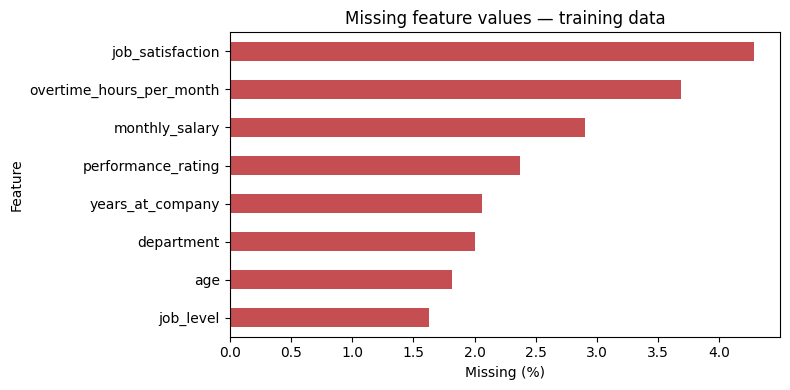

In [5]:
display(train.head())

summary = pd.DataFrame({
    "type": train.dtypes.astype(str),
    "missing": train.isna().sum(),
    "missing (%)": train.isna().mean() * 100,
    "unique_values": train.nunique(),
})

display(summary.round(2))

print("Repeated full source rows:", df.duplicated().sum())
print("Repeated predictor patterns in train:", train[FEATURES].duplicated().sum())
print("Missing or repeated employee IDs were checked before splitting.")

missing_share = train[FEATURES].isna().mean().mul(100).sort_values()

ax = missing_share.plot.barh(figsize=(8, 4), color="#C44E52")
ax.set(title="Missing feature values — training data", xlabel="Missing (%)", ylabel="Feature")
plt.tight_layout()
plt.show()


### Check ranges and category codes
Flags help identify possible data errors. They do not prove an error without a documented scale. Review flagged rows rather than silently deleting unusual employees.


**Code cell 6 — Check ranges and categories**

Summarizes numeric values and flags values outside the exercise checks. It also displays the frequency of each category, including missing values.

**Output:** Numeric statistics, flagged counts, and category tables. A flag needs investigation rather than automatic deletion.


In [6]:
display(train[NUMERIC + ["performance_rating"]].describe().round(2))

checks = {
    "age <= 0": (train["age"] <= 0).sum(),
    "years_at_company < 0": (train["years_at_company"] < 0).sum(),
    "monthly_salary <= 0": (train["monthly_salary"] <= 0).sum(),
    "overtime_hours_per_month < 0": (train["overtime_hours_per_month"] < 0).sum(),
    "job_satisfaction outside observed scale 1–100": (
        train["job_satisfaction"].notna() & ~train["job_satisfaction"].between(1, 100)
    ).sum(),
    "performance_rating outside codes 1–5": (
        train["performance_rating"].notna() & ~train["performance_rating"].isin([1, 2, 3, 4, 5])
    ).sum(),
}

display(pd.Series(checks, name="flagged_rows").to_frame())

for column in CATEGORICAL:
    print(f"\n{column}")
    display(train[column].value_counts(dropna=False).rename("rows").to_frame())


,age,years_at_company,monthly_salary,overtime_hours_per_month,job_satisfaction,performance_rating
count,3142.00,3134.00,3107.00,3082.00,3063.00,3124.00
mean,34.73,2.86,6404.55,6.77,59.99,2.97
std,8.22,2.54,3076.94,5.59,15.98,0.64
min,21.00,0.05,2350.00,0.00,1.00,1.00
25%,29.00,1.03,4200.00,3.00,49.00,3.00
50%,35.00,2.09,5500.00,5.00,60.00,3.00
75%,40.00,3.73,7700.00,9.00,70.00,3.00
max,62.00,22.00,24450.00,35.00,100.00,5.00


,flagged_rows
age <= 0,0
years_at_company < 0,0
monthly_salary <= 0,0
overtime_hours_per_month < 0,0
job_satisfaction outside observed scale 1–100,0
performance_rating outside codes 1–5,0



department


,rows
department,
Operations,515
Fulfillment,487
Customer Service,458
Retail Store,369
Sales,353
Marketing,246
Technology,219
Finance,185
Supply Chain,176



job_level


,rows
job_level,
Entry,1199
Mid,1115
Senior,606
Manager,228
NaN,52



performance_rating


,rows
performance_rating,
3.0,1899
2.0,646
4.0,557
NaN,76
5.0,12
1.0,10


### Check class balance
An always-stay classifier may look accurate when churn is rare. This is why we also measure precision, recall, F1 and average precision.


**Code cell 7 — Measure class imbalance**

Counts stay and churn labels, calculates their percentages, and shows how accurate an always-majority predictor would look.

**Output:** A balance table and bar chart. Use this to understand why accuracy alone can be misleading.


,rows,share (%)
churn,,
0,2808,87.75
1,392,12.25


Majority-only training accuracy: 87.75%


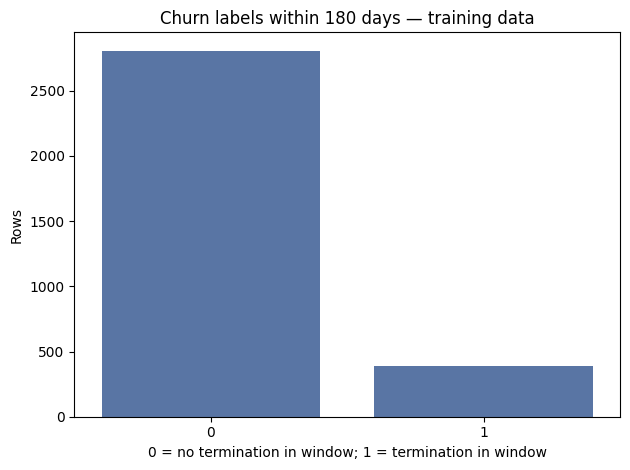

In [7]:
target_summary = train[TARGET].value_counts().reindex([0, 1], fill_value=0).to_frame("rows")
target_summary["share (%)"] = target_summary["rows"] / len(train) * 100

display(target_summary.round(2))
print(f"Majority-only training accuracy: {target_summary['share (%)'].max():.2f}%")

ax = sns.countplot(data=train, x=TARGET, order=[0, 1], color="#4C72B0")
ax.set(title=f"Churn labels within {HORIZON_DAYS} days — training data", xlabel="0 = no termination in window; 1 = termination in window", ylabel="Rows")
plt.tight_layout()
plt.show()


### Read numeric distributions
Histograms show where values are common and whether long tails exist. We do not remove a high salary just because it is unusual.


**Code cell 8 — Plot numeric distributions**

Assigns readable unit labels and draws one histogram per numeric feature. The unused sixth plot is hidden.

**Output:** Histograms of age, tenure, salary, overtime, and satisfaction. Look for common ranges and long tails.


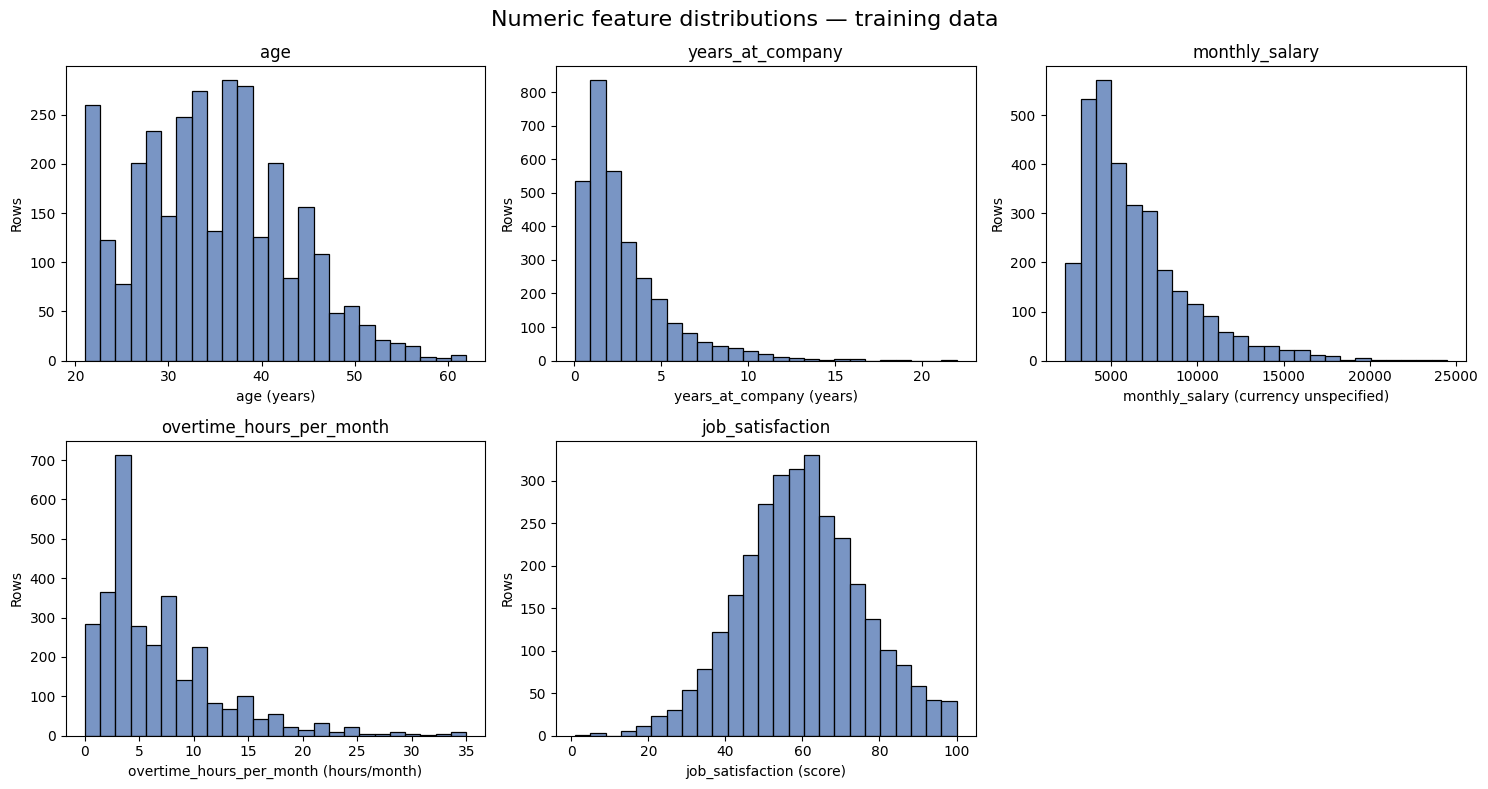

In [8]:
units = {"age": "years", "years_at_company": "years", "monthly_salary": "currency unspecified",
         "overtime_hours_per_month": "hours/month", "job_satisfaction": "score"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column in zip(axes.flat, NUMERIC):
    sns.histplot(data=train, x=column, bins=25, color="#4C72B0", ax=ax)
    ax.set(title=column, xlabel=f"{column} ({units[column]})", ylabel="Rows")

axes.flat[-1].set_visible(False)
fig.suptitle("Numeric feature distributions — training data", fontsize=16)
plt.tight_layout()
plt.show()


### Read category counts
Small groups provide less evidence. Missing categories are shown explicitly.


**Code cell 9 — Plot category frequencies**

Creates a plotting copy, labels missing categories, defines display order, and counts department, job level, and rating categories.

**Output:** Three category count charts. This changes plotting labels only; it does not modify model inputs.


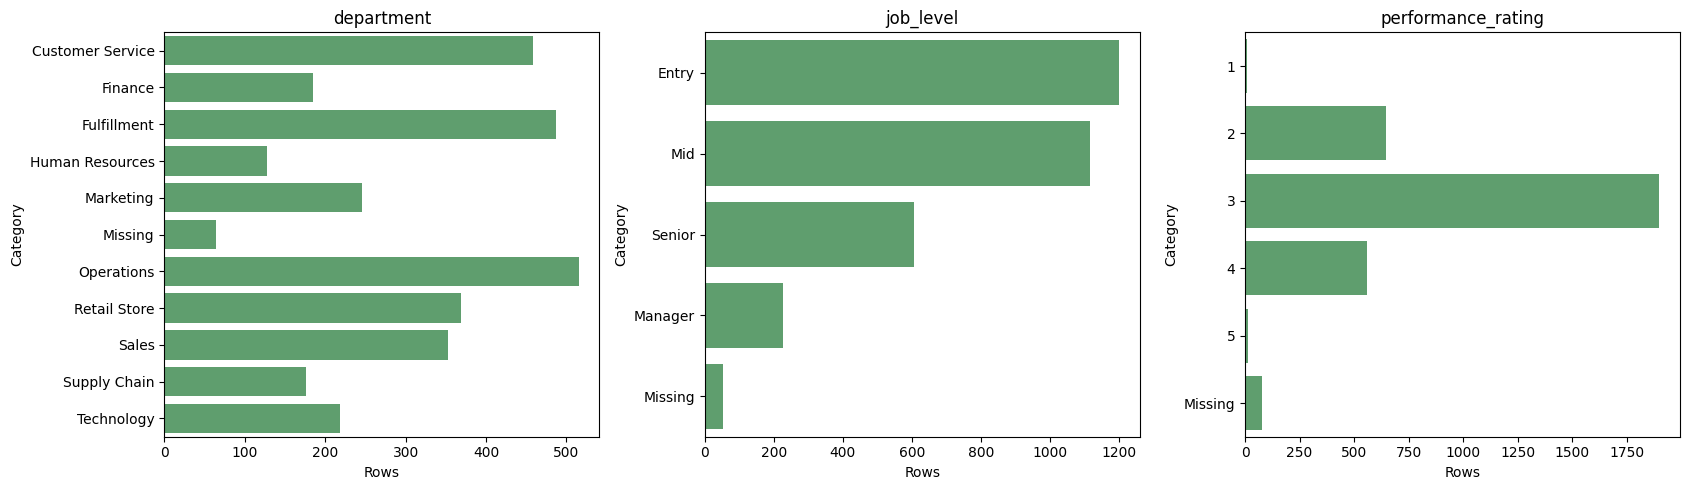

In [9]:
plot_data = train.copy()

for column in ["department", "job_level"]:
    plot_data[column] = plot_data[column].fillna("Missing")

plot_data["performance_rating"] = plot_data["performance_rating"].apply(
    lambda value: "Missing" if pd.isna(value) else str(int(value))
)

orders = {
    "department": sorted(plot_data["department"].unique()),
    "job_level": [level for level in ["Entry", "Mid", "Senior", "Manager", "Missing"] if level in plot_data["job_level"].values],
    "performance_rating": [level for level in ["1", "2", "3", "4", "5", "Missing"] if level in plot_data["performance_rating"].values],
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, column in zip(axes, CATEGORICAL):
    sns.countplot(data=plot_data, y=column, order=orders[column], color="#55A868", ax=ax)
    ax.set(title=column, xlabel="Rows", ylabel="Category")

plt.tight_layout()
plt.show()


### Compare distributions by churn
Separating the classes can suggest useful features. A difference is an association, not proof that the feature causes churn.


**Code cell 10 — Compare numeric features between classes**

Draws separate histograms for stay and churn employees. Density normalization makes the distributions comparable even when class sizes differ.

**Output:** Overlaid distributions. Differences suggest associations but do not prove causes of churn.


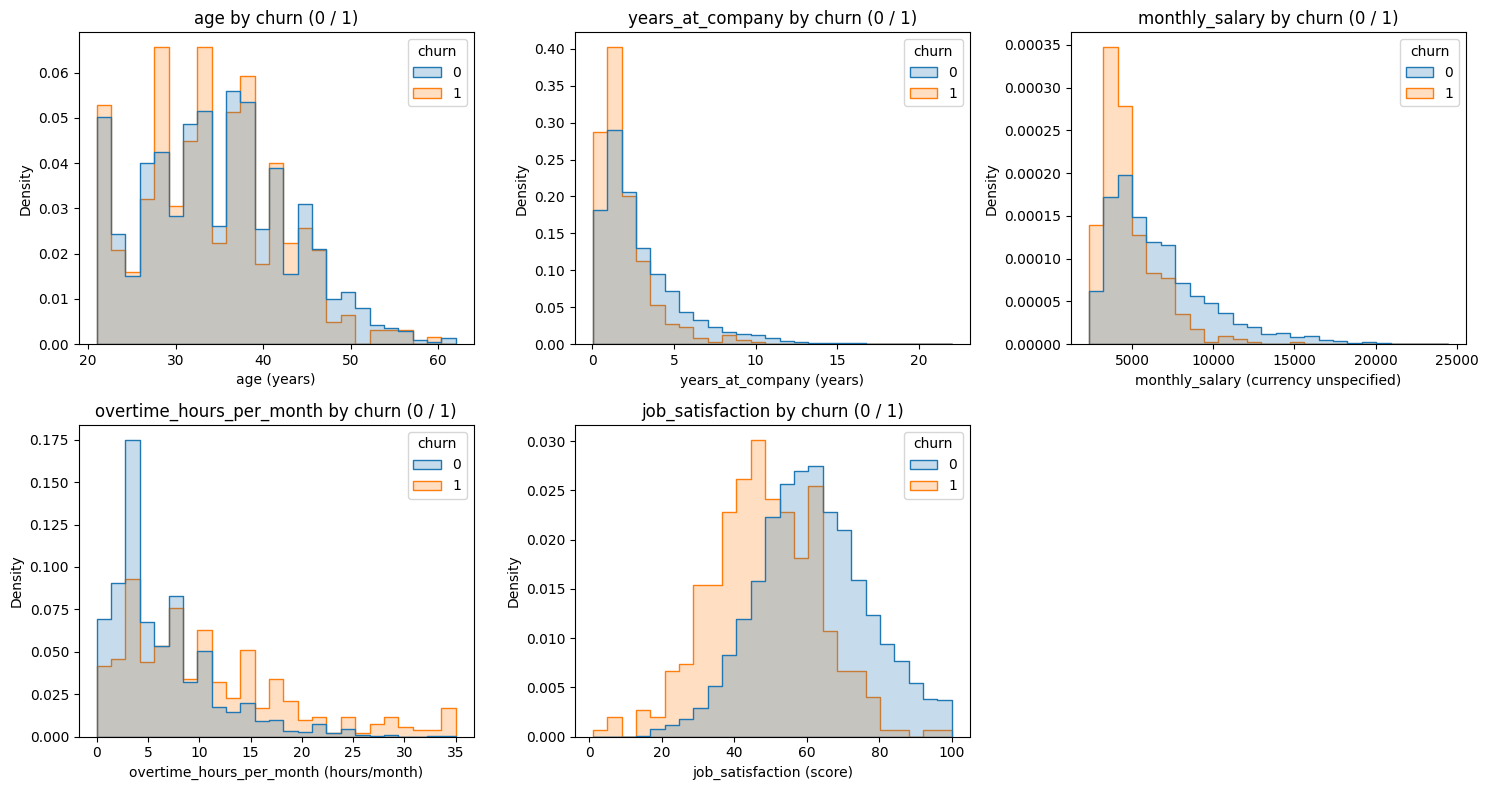

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column in zip(axes.flat, NUMERIC):
    sns.histplot(data=train, x=column, hue=TARGET, bins=25,
                 stat="density", common_norm=False, element="step", ax=ax)
    ax.set(title=f"{column} by churn (0 / 1)", xlabel=f"{column} ({units[column]})")

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()


### Compare category churn rates
Read the row counts beside the rates. A high rate in a tiny category may be unstable.


**Code cell 11 — Compare category churn rates**

Groups training employees by category, calculates row counts and churn percentages, and plots each category rate.

**Output:** Tables and horizontal bar charts. Read the row counts before trusting a high rate in a small group.



department


,rows,churn_rate
department,,
Customer Service,458,14.41
Finance,185,8.11
Fulfillment,487,18.89
Human Resources,128,9.38
Marketing,246,4.47
Missing,64,17.19
Operations,515,10.49
Retail Store,369,15.18
Sales,353,10.20



job_level


,rows,churn_rate
job_level,,
Entry,1199,20.35
Mid,1115,10.04
Senior,606,4.62
Manager,228,1.75
Missing,52,7.69



performance_rating


,rows,churn_rate
performance_rating,,
1,10,50.00
2,646,19.97
3,1899,12.11
4,557,2.87
5,12,0.00
Missing,76,15.79


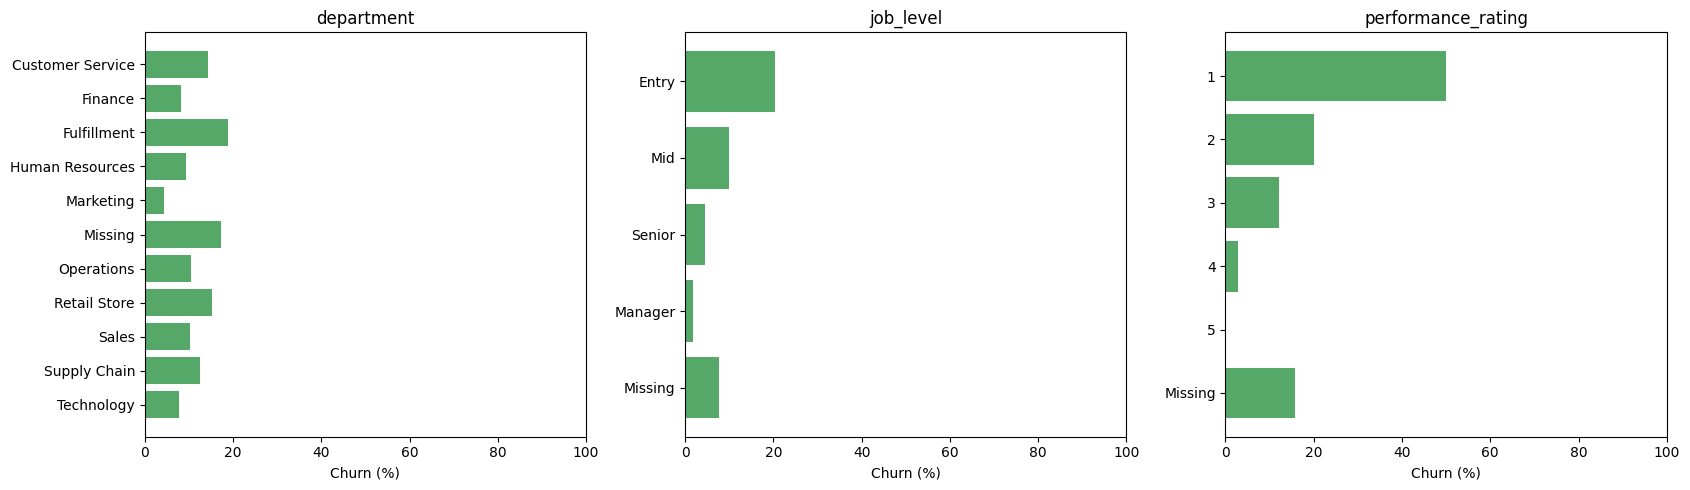

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, column in zip(axes, CATEGORICAL):
    group_summary = plot_data.groupby(column)[TARGET].agg(rows="size", churn_rate="mean").reindex(orders[column])
    group_summary["churn_rate"] *= 100

    print(f"\n{column}")
    display(group_summary.round(2))

    ax.barh(group_summary.index, group_summary["churn_rate"], color="#55A868")
    ax.invert_yaxis()
    ax.set(title=column, xlabel="Churn (%)", xlim=(0, 100))

plt.tight_layout()
plt.show()


### Compare satisfaction and overtime bands
These bands make the chart easier to read. Models still use the original numeric values; chart bands do not replace inputs.


**Code cell 12 — Compare satisfaction and overtime bands**

Places values into readable bands for charts, calculates each band’s churn share, and plots the results.

**Output:** Band summary tables and rate charts. The models still receive the original numeric features.


,rows,churn_rate
satisfaction_band,,
1–25,48,43.75
26–50,794,24.18
51–75,1719,8.84
76–100,502,2.39
Missing,137,10.95


,rows,churn_rate
overtime_band,,
0 hours,34,8.82
>0–5,1607,7.16
>5–10,849,12.25
>10–20,489,23.31
>20,103,38.83
Missing,118,13.56


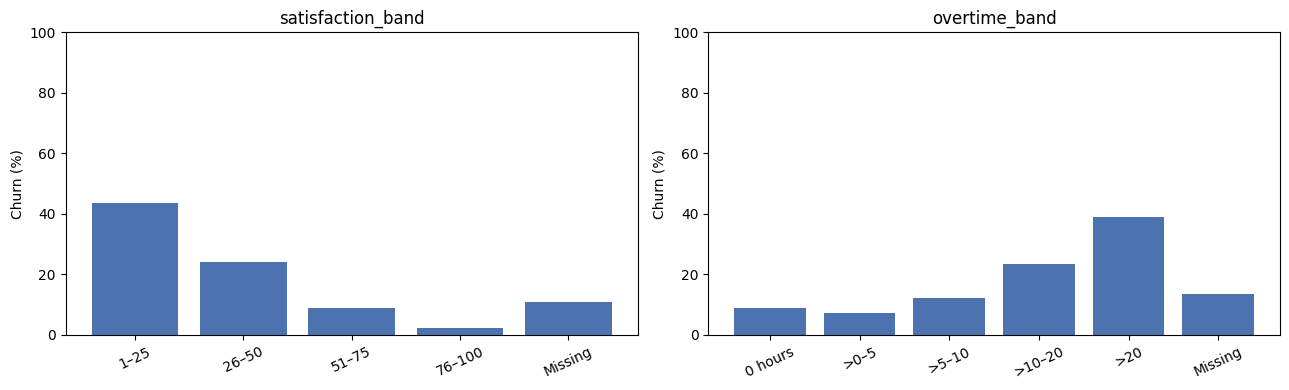

In [12]:
band_data = train.copy()

band_data["satisfaction_band"] = pd.cut(
    train["job_satisfaction"], bins=[0, 25, 50, 75, 100],
    labels=["1–25", "26–50", "51–75", "76–100"], include_lowest=True
).astype(object).fillna("Missing")

band_data["overtime_band"] = pd.cut(
    train["overtime_hours_per_month"], bins=[-np.inf, 0, 5, 10, 20, np.inf],
    labels=["0 hours", ">0–5", ">5–10", ">10–20", ">20"]
).astype(object).fillna("Missing")

band_orders = {"satisfaction_band": ["1–25", "26–50", "51–75", "76–100", "Missing"],
               "overtime_band": ["0 hours", ">0–5", ">5–10", ">10–20", ">20", "Missing"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, column in zip(axes, band_orders):
    group_summary = band_data.groupby(column)[TARGET].agg(rows="size", churn_rate="mean").reindex(band_orders[column])
    group_summary["churn_rate"] *= 100

    display(group_summary.round(2))

    ax.bar(group_summary.index, group_summary["churn_rate"], color="#4C72B0")
    ax.set(title=column, ylabel="Churn (%)", ylim=(0, 100))
    ax.tick_params(axis="x", labelrotation=25)

plt.tight_layout()
plt.show()


### Inspect correlations
Spearman correlation compares ranks and can show monotonic relationships. It does not capture every interaction. Numeric rating codes are used only for this descriptive chart; the models one-hot encode them.


**Code cell 13 — Calculate rank correlations**

Computes Spearman correlations for numeric features, rating codes, and churn, then displays a heatmap.

**Output:** A matrix with values from −1 to 1. It summarizes rank associations, not every possible interaction.


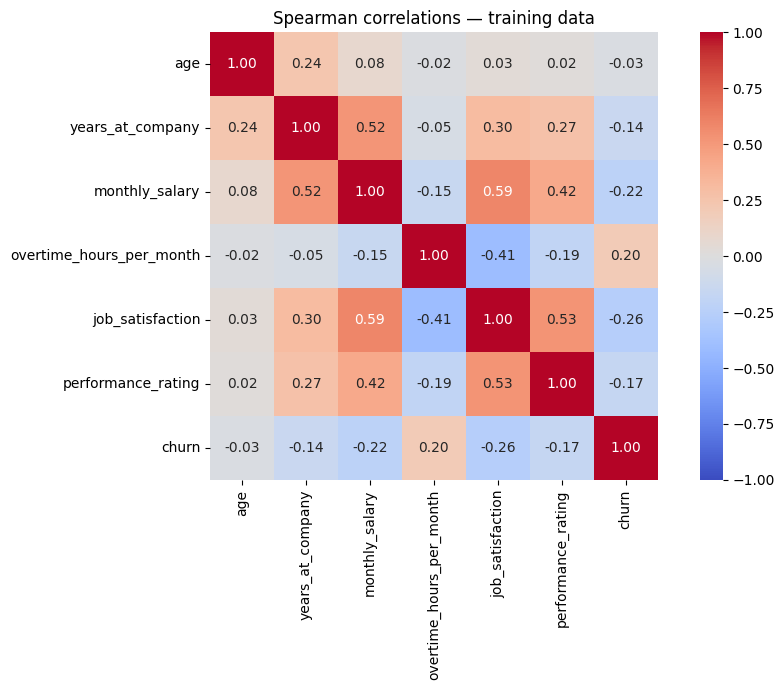

In [13]:
correlation_columns = NUMERIC + ["performance_rating", TARGET]

plt.figure(figsize=(10, 7))

correlation = train[correlation_columns].corr(method="spearman")

sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True)
plt.title("Spearman correlations — training data")
plt.tight_layout()
plt.show()


### Compare average values
This cell now follows the split, so `train` exists. Group means are descriptive; distributions and sample counts still matter.


**Code cell 14 — Compare class averages**

Groups the training data by churn and computes mean values for selected columns.

**Output:** One row per class with average feature values. Use this together with the distribution charts.


In [14]:
columns = [
    "age",
    "years_at_company",
    "monthly_salary",
    "overtime_hours_per_month",
    "job_satisfaction",
    "performance_rating",
]

display(train.groupby("churn")[columns].mean().round(2))


,age,years_at_company,monthly_salary,overtime_hours_per_month,job_satisfaction,performance_rating
churn,,,,,,
0,34.82,2.99,6628.98,6.24,61.63,3.01
1,34.07,1.95,4798.82,10.61,48.25,2.68


## 4. Prepare the inputs with pandas
We replace the longer preprocessing pipeline with direct pandas steps.

1. Select the eight features. Leave out IDs and termination dates.
2. Fill numeric gaps using **training medians**. A median is less affected by very large values than a mean.
3. Fill category gaps with `Missing`, then use `get_dummies()` to create one column per category. We do not treat category codes as measured distances.
4. Give validation and test exactly the training columns. A new category becomes zeros in the known columns.
5. Standardize numeric columns for neural networks using training means and standard deviations. Trees use the unscaled version because their splits depend on ordering.

The small `encode_features()` function repeats steps 1–4. Its first argument is always the data allowed to teach the cleaning steps. Its second argument is transformed using those steps. The same rule applies inside MTKD folds.


**Code cell 15 — Fill missing values and encode categories**

Defines `encode_features()`. It learns numeric medians and category columns from its first dataset and applies them to the second dataset. It then prepares training, validation, and test features without IDs or outcome dates.

**Output:** Encoded feature tables and unscaled arrays for trees. Unknown categories cannot add new predictor columns.


In [15]:
def encode_features(training_data, new_data):
    training_features = training_data[FEATURES].copy()
    new_features = new_data[FEATURES].copy()

    for column in NUMERIC:
        training_features[column] = pd.to_numeric(training_features[column], errors='raise')
        new_features[column] = pd.to_numeric(new_features[column], errors='raise')

        if np.isinf(training_features[column].dropna()).any() or np.isinf(new_features[column].dropna()).any():
            raise ValueError(f'Infinite values in {column}')

        median = training_features[column].median()
        if pd.isna(median):
            median = 0  # Keeps a completely missing numeric column usable.

        training_features[column] = training_features[column].fillna(median)
        new_features[column] = new_features[column].fillna(median)

    for column in CATEGORICAL:

        training_features[column] = training_features[column].fillna('Missing').astype(str)
        new_features[column] = new_features[column].fillna('Missing').astype(str)

    training_features = pd.get_dummies(training_features, columns=CATEGORICAL, dtype=float)
    new_features = pd.get_dummies(new_features, columns=CATEGORICAL, dtype=float)

    new_features = new_features.reindex(columns=training_features.columns, fill_value=0)

    return training_features, new_features

train_features, val_features = encode_features(train, val)
_, test_features = encode_features(train, test)

# Trees use these unscaled values.
X_train_tree = train_features.to_numpy(dtype=np.float32)
X_val_tree = val_features.to_numpy(dtype=np.float32)
X_test_tree = test_features.to_numpy(dtype=np.float32)


### Scale numeric columns
`fit_transform` learns the training statistics. `transform` reuses them for other data. One-hot category columns stay as zeros and ones.


**Code cell 16 — Scale neural inputs and prepare labels**

Fits a scaler on training numeric columns, reuses it on validation/test columns, and converts the tables and labels to NumPy arrays. One-hot columns are not scaled.

**Output:** `X_train`, `X_val`, `X_test`, the three label arrays, and the encoded feature count.


In [16]:
scaler = StandardScaler()

train_scaled = train_features.copy()
val_scaled = val_features.copy()
test_scaled = test_features.copy()

train_scaled[NUMERIC] = scaler.fit_transform(train_features[NUMERIC])
val_scaled[NUMERIC] = scaler.transform(val_features[NUMERIC])
test_scaled[NUMERIC] = scaler.transform(test_features[NUMERIC])

X_train = train_scaled.to_numpy(dtype=np.float32)
X_val = val_scaled.to_numpy(dtype=np.float32)
X_test = test_scaled.to_numpy(dtype=np.float32)

y_train = train['churn'].to_numpy(dtype=np.int64)
y_val = val['churn'].to_numpy(dtype=np.int64)
y_test = test['churn'].to_numpy(dtype=np.int64)

input_size = X_train.shape[1]
print('Input features after encoding:', input_size)


Input features after encoding: 27


## 5. Fixed experiment settings and a basic neural network
These are reasonable starting choices for a small tabular learning exercise. They are **not proven optimal** and were not selected from test results.

| Setting | Value | Reason and tradeoff |
|---|---|---|
| Seed | 42 | Repeatable initialization and shuffling; one seed cannot show run-to-run uncertainty |
| Activation | ReLU | Adds nonlinear relationships with simple computation |
| Output | Two logits | One score for each class; softmax turns them into probabilities |
| Hard-label loss | Cross-entropy, no class weights | Trains classification probabilities; imbalance is made visible through metrics rather than changed probability costs |
| Optimizer | Adam | Adapts update sizes for different weights |
| Learning rate | 0.001 | A modest starting step; too high may oscillate, too low may learn slowly |
| Adam betas / epsilon | 0.9, 0.999 / 1e-8 | Smooth gradient estimates and avoid unstable division |
| Weight decay | 0.0001 | Mild pressure against large weights; excessive decay can underfit |
| Batch size | 64 | Balances update frequency and memory for a small dataset |
| Dense/LTH/student epochs | 150 | A fixed, manageable training budget; training losses and final validation metrics help diagnose the budget |
| Teacher epochs | 100 | Fixed budget for each larger teacher, including cross-fitting |
| Dropout | None | Keeps pruning and distillation comparisons simple; decay limits weights |
| Class decision threshold | 0.5 for all | Clear common rule, not a business-optimized threshold |

**Fixed means:** every run uses the final epoch. No early stopping, best-epoch selection, or parameter search is used. Validation and test scores are logged every epoch for diagnosis; only validation AP selects the method recommendation. We do not oversample or use SMOTE. If recall is weak, a later experiment may choose a threshold on validation data, but that would be a separate decision before a fresh final evaluation.


**Code cell 17 — Set fixed settings and define a network**

Sets epochs, pruning rates, loss weights, and `LOG_EVERY = 10`. `make_network()` builds two hidden layers; `predict()` converts two class scores into probabilities. It also creates the history container.

**Output:** Reusable functions and settings. Defining them does not start training. `[:, 1]` later selects the churn probability.


In [17]:
# Plain variables make the settings easy to find and understand.
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

BATCH_SIZE = 64
EPOCHS = 150
TEACHER_EPOCHS = 100
BOOSTING_ROUNDS = 400

PRUNING_ROUNDS = 5
HIDDEN_PRUNE_RATE = 0.20
OUTPUT_PRUNE_RATE = 0.10

TEMPERATURE = 2.0
LABEL_WEIGHT = 0.5

THRESHOLD = 0.5
LOG_EVERY = 10

# Two hidden layers, followed by two class scores: Stay and Churn.
def make_network(number_of_inputs, first_size, second_size):
    return nn.Sequential(
        nn.Linear(number_of_inputs, first_size),
        nn.ReLU(),
        nn.Linear(first_size, second_size),
        nn.ReLU(),
        nn.Linear(second_size, 2)
    ).to(device)

# Convert model scores into class probabilities.
def predict(model, inputs):
    model.eval()

    inputs = torch.tensor(inputs, dtype=torch.float32, device=device)

    with torch.no_grad():
        scores = model(inputs)
        probabilities = torch.softmax(scores, dim=1)

    return probabilities.cpu().numpy()

# Progress updates each epoch; score messages appear every LOG_EVERY epochs.
# Fold plots are optional because there are nine OOF runs.
SHOW_FOLD_PLOTS = False
training_runs = {}


### A reusable training loop
The loop has five main steps: predict → calculate loss → clear old gradients → calculate new gradients → update weights. A batch is a small group of employees. An epoch means working through all training employees once.

`masks=None` means ordinary dense training. For LTH, we pass three masks, one per linear layer. Removed connections receive zero gradients and are set to zero after every update. This prevents them from returning. Biases are not pruned.

This function trains only on true labels. Student distillation has its own short loop later, so its different loss is visible.


### Performance after every epoch
This version increases dense, LTH and student training from **60 to 150 epochs**, and teachers from **50 to 100 epochs**. More epochs give the optimizer more updates; they do not guarantee better validation performance. XGBoost uses **400 boosting rounds**, increased from 300. A boosting round adds a tree; it is different from a neural-network epoch.

Every neural run records **training loss, validation accuracy/F1/AP/log loss, and test accuracy/F1/AP/log loss** after every epoch. A `tqdm` bar tracks progress; score messages appear every **10 epochs** and at the final epoch. Scores are computed with no gradients. The final epoch remains the output; we do not pick the epoch with the best test score or use early stopping. OOF teacher logs use the held-out training fold as their validation data, and the common test set transformed by that fold's training-only preprocessing.

**Monitoring protocol:** the test set is now visible during training, as requested. It does not train the model, aggregator, scaler, or masks. However, if you change settings because of its curve, it becomes a development set and you will need a fresh untouched test set for a final estimate. Keep the settings fixed for this run. Validation AP alone gives the method recommendation.

Read the curves together: falling training loss with worsening validation loss can suggest overfitting. AP describes ranking; F1 and accuracy use the fixed 0.5 threshold. A high accuracy can still hide low churn recall. The student training objective is a mixture of label and distillation losses, while its validation/test log loss uses only actual labels; these loss values have different meanings.

`training_runs` stores each run's history and final predictions. Learning curves and confusion matrices appear after training. Matrices use the final epoch of each run, rather than producing hundreds of matrices. Set `SHOW_FOLD_PLOTS = True` to also plot the nine OOF teacher runs; their epoch scores are recorded every epoch and printed every 10 epochs either way.


**Code cell 18 — Define training and monitoring helpers**

`performance_scores()` calculates metrics. `monitor_epoch()` measures validation/test performance and prints every 10 epochs. `train_network()` updates model weights batch by batch, applies LTH masks when supplied, and stores every epoch’s metrics.

**Output:** Function definitions. Actual training begins when later cells call them; monitoring never sends validation/test gradients to the optimizer.


### How progress and logging work
`LOG_EVERY = 10` prints scores at 10, 20, 30, and so on. The final epoch/round also prints if it is not a multiple of 10. Progress advances after every epoch/round. Metrics are still calculated and saved every time, so curves retain all points. `tqdm.write()` prints messages without damaging the progress bar. The XGBoost callback reports progress without changing training or stopping it. See [tqdm documentation](https://tqdm.github.io/docs/tqdm/) and [XGBoost callbacks](https://xgboost.readthedocs.io/en/stable/python/callbacks.html).


In [18]:
def performance_scores(labels, probabilities):
    predictions = (probabilities >= THRESHOLD).astype(int)

    return {
        'accuracy': accuracy_score(labels, predictions),
        'F1': f1_score(labels, predictions, zero_division=0),
        'AP': average_precision_score(labels, probabilities),
        'logloss': log_loss(labels, probabilities, labels=[0, 1])
    }


def monitor_epoch(model, run_name, epoch, training_loss, validation_data, test_data, total_epochs):
    val_inputs, val_labels = validation_data
    test_inputs, test_labels = test_data

    val_scores = performance_scores(val_labels, predict(model, val_inputs)[:, 1])
    test_scores = performance_scores(test_labels, predict(model, test_inputs)[:, 1])

    row = {'epoch': epoch, 'training_loss': training_loss}

    for metric in val_scores:
        row['val_' + metric] = val_scores[metric]
        row['test_' + metric] = test_scores[metric]

    if epoch % LOG_EVERY == 0 or epoch == total_epochs:
        tqdm.write(
            f"{run_name} | Epoch {epoch:03d} | Train loss {training_loss:.4f} | "
            f"Val: loss {val_scores['logloss']:.4f}, acc {val_scores['accuracy']:.4f}, "
            f"F1 {val_scores['F1']:.4f}, AP {val_scores['AP']:.4f} | "
            f"Test: loss {test_scores['logloss']:.4f}, acc {test_scores['accuracy']:.4f}, "
            f"F1 {test_scores['F1']:.4f}, AP {test_scores['AP']:.4f}"
        )

    return row


def save_training_run(model, run_name, history, validation_data, test_data):
    val_inputs, val_labels = validation_data
    test_inputs, test_labels = test_data

    # Store the final probabilities now, before a later pruning round changes the model.
    training_runs[run_name] = {
        'history': pd.DataFrame(history),
        'val_labels': val_labels.copy(),
        'test_labels': test_labels.copy(),
        'val_probabilities': predict(model, val_inputs)[:, 1],
        'test_probabilities': predict(model, test_inputs)[:, 1]
    }


def train_network(model, inputs, labels, epochs, masks=None,
                  run_name='Neural network', validation_data=None, test_data=None):
    # Main models monitor the common validation/test splits.
    # OOF teachers pass their fold-specific transformed data explicitly.
    if validation_data is None:
        validation_data = (X_val, y_val)

    if test_data is None:
        test_data = (X_test, y_test)

    inputs = torch.tensor(inputs, dtype=torch.float32)
    labels = torch.tensor(labels, dtype=torch.long)

    dataset = TensorDataset(inputs, labels)
    batches = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE,
                                 weight_decay=WEIGHT_DECAY)
    loss_function = nn.CrossEntropyLoss()

    losses = []
    history = []
    linear_layers = [model[0], model[2], model[4]]

    progress = tqdm(range(epochs), desc=run_name, unit='epoch')

    for epoch in progress:
        model.train()
        total_loss = 0

        for batch_inputs, batch_labels in batches:
            batch_inputs = batch_inputs.to(device)
            batch_labels = batch_labels.to(device)

            scores = model(batch_inputs)
            loss = loss_function(scores, batch_labels)

            optimizer.zero_grad()
            loss.backward()

            if masks is not None:
                for layer, mask in zip(linear_layers, masks):
                    layer.weight.grad *= mask

            optimizer.step()

            if masks is not None:
                with torch.no_grad():
                    for layer, mask in zip(linear_layers, masks):
                        layer.weight *= mask

            total_loss += loss.item() * len(batch_labels)

        average_loss = total_loss / len(dataset)
        losses.append(average_loss)

        row = monitor_epoch(model, run_name, epoch + 1, average_loss,
                            validation_data, test_data, epochs)
        history.append(row)

        if (epoch + 1) % LOG_EVERY == 0 or epoch + 1 == epochs:
            progress.set_postfix(val_AP=f"{row['val_AP']:.3f}",
                                 test_AP=f"{row['test_AP']:.3f}")

    save_training_run(model, run_name, history, validation_data, test_data)

    return losses


## 6. Method 1 — Lottery Ticket Hypothesis
Start with a dense network with hidden layers **64 → 32**. Save its initial weights before training. Train it, remove low-magnitude connections, reset surviving weights to their original values, and train again with a fresh optimizer. Repeat pruning five times.

A **mask** contains ones for surviving connections and zeros for removed connections. Gradients and weights are masked, so removed connections stay zero. Biases are kept and reset to their original values.

| LTH choice | Value | Why we choose it |
|---|---|---|
| Hidden layers | 64, 32 | Enough capacity to learn interactions without a very large model |
| Pruning rule | Smallest absolute trained weights within each layer | A clear importance proxy; magnitude alone does not prove a connection is useless |
| Hidden-layer pruning | 20% of remaining weights each round | Gradual removal; after five rounds roughly 0.8^5 = 32.8% remain |
| Output pruning | 10% of remaining weights each round | More conservative removal in the small decision layer; roughly 59% remain |
| Rounds | 5 | Shows progressive sparsity while keeping search cost manageable |
| Reset point | Original initialization | Tests the central LTH initialization idea rather than fine-tuning trained weights |

The output layer uses integer rounding, so measured density may differ slightly. We retain every round's validation score and use the final round as the predeclared LTH result. A same-mask random reinitialization control checks whether the original values help. The dense model is also reported.

**Sparse weights do not automatically make this implementation smaller or faster.** It still uses dense tensors. We report active connections separately from allocated parameters. A winning ticket is an empirical claim; a single run cannot establish the hypothesis generally.


### Step 1: train the dense model
We save the initial values **before** training. The dense baseline is a copy of the trained model, so later pruning cannot change it.


**Code cell 19 — Train the dense LTH baseline**

Builds a 64 → 32 network, saves its original values, and trains it for 150 epochs. Copies the trained model and creates all-one masks before pruning.

**Output:** A tqdm bar, score messages at epochs 10, 20, and so on, and a saved dense baseline for comparison.


In [19]:
lth_start = time.perf_counter()

set_seed(SEED)
lth_model = make_network(input_size, 64, 32)
initial_weights = copy.deepcopy(lth_model.state_dict())

set_seed(SEED)
dense_losses = train_network(lth_model, X_train, y_train, EPOCHS, run_name='Dense baseline')
dense_model = copy.deepcopy(lth_model)

# A mask starts with ones: every weight is available.
masks = [torch.ones_like(lth_model[0].weight),
         torch.ones_like(lth_model[2].weight),
         torch.ones_like(lth_model[4].weight)]

remaining_weights = [1.0]
validation_AP = [average_precision_score(y_val, predict(dense_model, X_val)[:, 1])]


Dense baseline:   0%|          | 0/150 [00:00<?, ?epoch/s]

Dense baseline | Epoch 010 | Train loss 0.3135 | Val: loss 0.3399, acc 0.8775, F1 0.0577, AP 0.2973 | Test: loss 0.3455, acc 0.8740, F1 0.0870, AP 0.2719
Dense baseline | Epoch 020 | Train loss 0.3014 | Val: loss 0.3442, acc 0.8775, F1 0.1250, AP 0.2906 | Test: loss 0.3493, acc 0.8730, F1 0.1477, AP 0.2679
Dense baseline | Epoch 030 | Train loss 0.2856 | Val: loss 0.3548, acc 0.8700, F1 0.1333, AP 0.2738 | Test: loss 0.3664, acc 0.8660, F1 0.1625, AP 0.2571
Dense baseline | Epoch 040 | Train loss 0.2691 | Val: loss 0.3701, acc 0.8675, F1 0.1846, AP 0.2779 | Test: loss 0.3910, acc 0.8590, F1 0.2034, AP 0.2556
Dense baseline | Epoch 050 | Train loss 0.2530 | Val: loss 0.3917, acc 0.8712, F1 0.1760, AP 0.2646 | Test: loss 0.4166, acc 0.8650, F1 0.1818, AP 0.2441
Dense baseline | Epoch 060 | Train loss 0.2380 | Val: loss 0.3953, acc 0.8675, F1 0.1846, AP 0.2418 | Test: loss 0.4288, acc 0.8580, F1 0.1744, AP 0.2244
Dense baseline | Epoch 070 | Train loss 0.2239 | Val: loss 0.4148, acc 0.865

### Step 2: prune, reset, and retrain
`abs()` measures weight magnitude. We consider only connections whose mask is still one. `argsort()` lists them from smallest to largest. Setting their mask to zero removes them.

After pruning, `load_state_dict()` restores the saved original values, including biases. Applying masks keeps removed weights zero. Calling the training function creates a fresh Adam optimizer for every round.


**Code cell 20 — Run iterative pruning**

In each of five rounds, finds small active weights, removes them from masks, restores original values, and retrains for 150 epochs. Stores each round’s performance before the next round changes the model.

**Output:** One progress bar per round, ten-epoch score logs, a validation AP/density table, and a pruning chart.


LTH round 1:   0%|          | 0/150 [00:00<?, ?epoch/s]

LTH round 1 | Epoch 010 | Train loss 0.3124 | Val: loss 0.3410, acc 0.8788, F1 0.0762, AP 0.3015 | Test: loss 0.3451, acc 0.8760, F1 0.1014, AP 0.2725
LTH round 1 | Epoch 020 | Train loss 0.2995 | Val: loss 0.3471, acc 0.8762, F1 0.1239, AP 0.2822 | Test: loss 0.3529, acc 0.8680, F1 0.1200, AP 0.2595
LTH round 1 | Epoch 030 | Train loss 0.2836 | Val: loss 0.3595, acc 0.8725, F1 0.1639, AP 0.2690 | Test: loss 0.3725, acc 0.8650, F1 0.1509, AP 0.2394
LTH round 1 | Epoch 040 | Train loss 0.2680 | Val: loss 0.3749, acc 0.8638, F1 0.2270, AP 0.2649 | Test: loss 0.3998, acc 0.8540, F1 0.2065, AP 0.2396
LTH round 1 | Epoch 050 | Train loss 0.2530 | Val: loss 0.3976, acc 0.8662, F1 0.1575, AP 0.2454 | Test: loss 0.4193, acc 0.8580, F1 0.1647, AP 0.2298
LTH round 1 | Epoch 060 | Train loss 0.2390 | Val: loss 0.4061, acc 0.8638, F1 0.1926, AP 0.2392 | Test: loss 0.4365, acc 0.8520, F1 0.1778, AP 0.2207
LTH round 1 | Epoch 070 | Train loss 0.2245 | Val: loss 0.4289, acc 0.8638, F1 0.1679, AP 0.23

LTH round 2:   0%|          | 0/150 [00:00<?, ?epoch/s]

LTH round 2 | Epoch 010 | Train loss 0.3117 | Val: loss 0.3415, acc 0.8762, F1 0.0748, AP 0.3008 | Test: loss 0.3460, acc 0.8720, F1 0.0725, AP 0.2671
LTH round 2 | Epoch 020 | Train loss 0.3008 | Val: loss 0.3450, acc 0.8712, F1 0.0885, AP 0.2895 | Test: loss 0.3542, acc 0.8690, F1 0.1325, AP 0.2541
LTH round 2 | Epoch 030 | Train loss 0.2885 | Val: loss 0.3521, acc 0.8762, F1 0.1818, AP 0.2786 | Test: loss 0.3687, acc 0.8690, F1 0.1656, AP 0.2449
LTH round 2 | Epoch 040 | Train loss 0.2751 | Val: loss 0.3666, acc 0.8662, F1 0.2074, AP 0.2774 | Test: loss 0.3891, acc 0.8550, F1 0.1989, AP 0.2412
LTH round 2 | Epoch 050 | Train loss 0.2634 | Val: loss 0.3856, acc 0.8662, F1 0.1575, AP 0.2543 | Test: loss 0.4037, acc 0.8660, F1 0.1728, AP 0.2319
LTH round 2 | Epoch 060 | Train loss 0.2536 | Val: loss 0.3924, acc 0.8638, F1 0.1679, AP 0.2352 | Test: loss 0.4139, acc 0.8540, F1 0.1705, AP 0.2240
LTH round 2 | Epoch 070 | Train loss 0.2416 | Val: loss 0.4066, acc 0.8662, F1 0.1705, AP 0.24

LTH round 3:   0%|          | 0/150 [00:00<?, ?epoch/s]

...

LTH round 4:   0%|          | 0/150 [00:00<?, ?epoch/s]

LTH round 4 | Epoch 010 | Train loss 0.3117 | Val: loss 0.3397, acc 0.8775, F1 0.0577, AP 0.2999 | Test: loss 0.3455, acc 0.8750, F1 0.1135, AP 0.2732
LTH round 4 | Epoch 020 | Train loss 0.3028 | Val: loss 0.3429, acc 0.8712, F1 0.0885, AP 0.2956 | Test: loss 0.3504, acc 0.8710, F1 0.1342, AP 0.2690
LTH round 4 | Epoch 030 | Train loss 0.2922 | Val: loss 0.3493, acc 0.8688, F1 0.1463, AP 0.2799 | Test: loss 0.3597, acc 0.8670, F1 0.1529, AP 0.2597
LTH round 4 | Epoch 040 | Train loss 0.2800 | Val: loss 0.3576, acc 0.8688, F1 0.2336, AP 0.2811 | Test: loss 0.3751, acc 0.8580, F1 0.2022, AP 0.2567
LTH round 4 | Epoch 050 | Train loss 0.2678 | Val: loss 0.3715, acc 0.8688, F1 0.1600, AP 0.2633 | Test: loss 0.3889, acc 0.8650, F1 0.1615, AP 0.2427
LTH round 4 | Epoch 060 | Train loss 0.2575 | Val: loss 0.3803, acc 0.8675, F1 0.1846, AP 0.2529 | Test: loss 0.4022, acc 0.8530, F1 0.1788, AP 0.2313
LTH round 4 | Epoch 070 | Train loss 0.2464 | Val: loss 0.3998, acc 0.8675, F1 0.1587, AP 0.24

LTH round 5:   0%|          | 0/150 [00:00<?, ?epoch/s]

LTH round 5 | Epoch 010 | Train loss 0.3120 | Val: loss 0.3395, acc 0.8762, F1 0.0748, AP 0.2958 | Test: loss 0.3450, acc 0.8750, F1 0.1259, AP 0.2746
LTH round 5 | Epoch 020 | Train loss 0.3043 | Val: loss 0.3434, acc 0.8725, F1 0.0727, AP 0.2936 | Test: loss 0.3504, acc 0.8730, F1 0.1477, AP 0.2693
LTH round 5 | Epoch 030 | Train loss 0.2958 | Val: loss 0.3477, acc 0.8725, F1 0.1207, AP 0.2849 | Test: loss 0.3582, acc 0.8690, F1 0.1656, AP 0.2601
LTH round 5 | Epoch 040 | Train loss 0.2859 | Val: loss 0.3534, acc 0.8712, F1 0.2016, AP 0.2902 | Test: loss 0.3704, acc 0.8570, F1 0.1538, AP 0.2559
LTH round 5 | Epoch 050 | Train loss 0.2748 | Val: loss 0.3645, acc 0.8675, F1 0.1167, AP 0.2731 | Test: loss 0.3827, acc 0.8630, F1 0.1595, AP 0.2405
LTH round 5 | Epoch 060 | Train loss 0.2661 | Val: loss 0.3683, acc 0.8738, F1 0.1513, AP 0.2640 | Test: loss 0.3929, acc 0.8600, F1 0.1667, AP 0.2329
LTH round 5 | Epoch 070 | Train loss 0.2567 | Val: loss 0.3801, acc 0.8725, F1 0.1500, AP 0.26

,round,weight_density,validation_AP
0,0,1.0000,0.2019
1,1,0.8021,0.2069
2,2,0.6438,0.2077
3,3,0.5167,0.2102
4,4,0.4148,0.2212
5,5,0.3333,0.2313


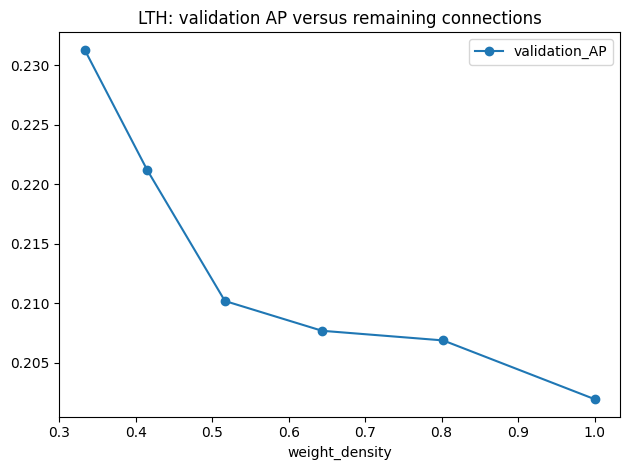

In [20]:
for round_number in range(PRUNING_ROUNDS):
    linear_layers = [lth_model[0], lth_model[2], lth_model[4]]
    pruning_rates = [HIDDEN_PRUNE_RATE, HIDDEN_PRUNE_RATE, OUTPUT_PRUNE_RATE]

    for layer, mask, rate in zip(linear_layers, masks, pruning_rates):
        flat_mask = mask.view(-1)
        flat_weights = layer.weight.detach().view(-1)
        active_indices = torch.where(flat_mask == 1)[0]
        number_to_remove = int(len(active_indices) * rate)

        # Keep at least one active connection in each layer.
        number_to_remove = min(number_to_remove, len(active_indices) - 1)

        magnitudes = flat_weights[active_indices].abs()
        smallest_first = torch.argsort(magnitudes, stable=True)
        remove_indices = active_indices[smallest_first[:number_to_remove]]

        flat_mask[remove_indices] = 0

    lth_model.load_state_dict(initial_weights)

    with torch.no_grad():
        for layer, mask in zip(linear_layers, masks):
            layer.weight *= mask

    set_seed(SEED)
    lth_losses = train_network(lth_model, X_train, y_train, EPOCHS, masks,
                               run_name=f'LTH round {round_number + 1}')

    active = sum(mask.sum().item() for mask in masks)
    total = sum(mask.numel() for mask in masks)
    remaining_weights.append(active / total)

    probabilities = predict(lth_model, X_val)[:, 1]
    validation_AP.append(average_precision_score(y_val, probabilities))

    print('Completed pruning round:', round_number + 1)

lth_seconds = time.perf_counter() - lth_start

lth_summary = pd.DataFrame({'round': range(PRUNING_ROUNDS + 1),
                           'weight_density': remaining_weights,
                           'validation_AP': validation_AP})

display(lth_summary.round(4))

lth_summary.plot(x='weight_density', y='validation_AP', marker='o')
plt.title('LTH: validation AP versus remaining connections')
plt.tight_layout()
plt.show()


### Step 3: test a different initialization
This control keeps the final mask, but starts with new random values. It helps check whether the original initialization was useful. The mask itself is unchanged.


**Code cell 21 — Train a random-initialization control**

Builds a new 64 → 32 network with different random values, applies the final LTH mask, and trains using the same epoch budget.

**Output:** Progress and score logs for a same-mask control. Compare this with the final original-initialization ticket.


In [21]:
set_seed(SEED + 100)
random_ticket = make_network(input_size, 64, 32)

with torch.no_grad():
    for layer, mask in zip([random_ticket[0], random_ticket[2], random_ticket[4]], masks):
        layer.weight *= mask

set_seed(SEED)
random_losses = train_network(random_ticket, X_train, y_train, EPOCHS, masks,
                              run_name='LTH random initialization')


LTH random initialization:   0%|          | 0/150 [00:00<?, ?epoch/s]

LTH random initialization | Epoch 010 | Train loss 0.3167 | Val: loss 0.3400, acc 0.8775, F1 0.0755, AP 0.3017 | Test: loss 0.3388, acc 0.8750, F1 0.1007, AP 0.2796
LTH random initialization | Epoch 020 | Train loss 0.3115 | Val: loss 0.3423, acc 0.8788, F1 0.1101, AP 0.2976 | Test: loss 0.3419, acc 0.8740, F1 0.1486, AP 0.2800
LTH random initialization | Epoch 030 | Train loss 0.3072 | Val: loss 0.3447, acc 0.8762, F1 0.1391, AP 0.2946 | Test: loss 0.3448, acc 0.8730, F1 0.1806, AP 0.2777
LTH random initialization | Epoch 040 | Train loss 0.3031 | Val: loss 0.3469, acc 0.8712, F1 0.1760, AP 0.2912 | Test: loss 0.3488, acc 0.8660, F1 0.1829, AP 0.2767
LTH random initialization | Epoch 050 | Train loss 0.2980 | Val: loss 0.3501, acc 0.8775, F1 0.1695, AP 0.2857 | Test: loss 0.3517, acc 0.8720, F1 0.1795, AP 0.2707
LTH random initialization | Epoch 060 | Train loss 0.2936 | Val: loss 0.3511, acc 0.8738, F1 0.1653, AP 0.2810 | Test: loss 0.3552, acc 0.8700, F1 0.1772, AP 0.2683
LTH random

## 7. Method 2 — Adapted multi-teacher knowledge distillation
A **teacher** learns from true labels. An **aggregator** learns how to combine the teachers' predictions. A smaller **student** learns from both the true label and the aggregator's soft prediction, such as a 0.25 chance of churn.

We use three neural teachers with widths **128 → 64**, **64 → 32**, and **128 → 32**, with different seeds. Different shapes and initializations may make different errors; diversity is not guaranteed. The student uses **32 → 16**, so it allocates fewer parameters than each teacher.

### Why cross-fitting is needed
Training an aggregator on teachers' own training predictions can encourage it to learn unrealistically confident answers. We divide the training set into **three stratified folds**. For each fold, teachers and preprocessing learn only from the other two folds; they predict the held-out fold. Every training employee gets three **out-of-fold (OOF)** probabilities. These become the aggregator's three input columns. True training labels teach the aggregator. Validation and test never train it.

A logistic-regression aggregator with **C = 1**, L2 regularization, and **max_iter = 1000** provides a simple learned combination with limited capacity and time to converge. C controls inverse regularization strength; max_iter is a solver budget. The full teachers are then trained on the full training set for later predictions. Their input distribution may differ from fold-trained teachers; validation scores help reveal this limitation.

### Student loss
`total loss = 0.5 × true-label cross-entropy + 0.5 × T² × KL divergence`

KL divergence measures the difference between the softened teacher and student class probabilities. Temperature **T = 2** softens confident predictions so the student can learn graded uncertainty. T² balances the change in gradient scale caused by temperature. Equal weights give both labels and teachers a role; teacher mistakes can still hurt the student. These choices are our classification experiment settings, not the image paper's loss or alpha value. See [classification distillation](https://arxiv.org/abs/1503.02531).

We soften the aggregator's probability by converting it to log probability, dividing by T, then applying softmax. Soft targets are detached constants. Teachers and aggregation weights are frozen while the student trains. A student with the same initialization trained only on labels is a control: compare it with the distilled student to see whether distillation helped.


### Step 1: create out-of-fold teacher predictions
We retain three-fold cross-fitting, but show it as a direct loop. Every held-out fold gets its own cleaning and scaling based only on the other folds. There is no early stopping on the held-out fold.


**Code cell 22 — Create OOF teacher predictions**

Uses three folds of training employees. Each fold learns its own preprocessing and trains three teachers on the other two folds. Teachers predict employees they did not train on. Fold-transformed test data is used only for monitoring.

**Output:** Nine teacher progress bars and a three-column OOF prediction array. The log’s validation data is the held-out training fold.


In [22]:
mtkd_start = time.perf_counter()

teacher_sizes = [(128, 64), (64, 32), (128, 32)]
teacher_seeds = [SEED + 10, SEED + 20, SEED + 30]

# One row per training employee, one column per teacher.
oof_predictions = np.zeros((len(train), 3))
folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

for fold_number, (learn_indices, hold_indices) in enumerate(folds.split(train, y_train)):
    learn_rows = train.iloc[learn_indices]
    hold_rows = train.iloc[hold_indices]

    learn_features, hold_features = encode_features(learn_rows, hold_rows)
    _, fold_test_features = encode_features(learn_rows, test)

    fold_scaler = StandardScaler()
    learn_features[NUMERIC] = fold_scaler.fit_transform(learn_features[NUMERIC])
    hold_features[NUMERIC] = fold_scaler.transform(hold_features[NUMERIC])
    fold_test_features[NUMERIC] = fold_scaler.transform(fold_test_features[NUMERIC])

    learn_inputs = learn_features.to_numpy(dtype=np.float32)
    hold_inputs = hold_features.to_numpy(dtype=np.float32)
    fold_test_inputs = fold_test_features.to_numpy(dtype=np.float32)

    for teacher_number in range(3):
        first_size, second_size = teacher_sizes[teacher_number]
        seed = teacher_seeds[teacher_number] + fold_number

        set_seed(seed)
        teacher = make_network(learn_inputs.shape[1], first_size, second_size)

        run_name = f'OOF fold {fold_number + 1} teacher {teacher_number + 1}'
        train_network(
            teacher, learn_inputs, y_train[learn_indices], TEACHER_EPOCHS,
            run_name=run_name,
            validation_data=(hold_inputs, y_train[hold_indices]),
            test_data=(fold_test_inputs, y_test)
        )

        oof_predictions[hold_indices, teacher_number] = predict(teacher, hold_inputs)[:, 1]

    print('Completed teacher fold:', fold_number + 1)


OOF fold 1 teacher 1:   0%|          | 0/100 [00:00<?, ?epoch/s]

OOF fold 1 teacher 1 | Epoch 010 | Train loss 0.3087 | Val: loss 0.3209, acc 0.8791, F1 0.1677, AP 0.3492 | Test: loss 0.3502, acc 0.8660, F1 0.1184, AP 0.2574
OOF fold 1 teacher 1 | Epoch 020 | Train loss 0.2802 | Val: loss 0.3421, acc 0.8810, F1 0.1477, AP 0.3145 | Test: loss 0.3776, acc 0.8680, F1 0.1081, AP 0.2220
OOF fold 1 teacher 1 | Epoch 030 | Train loss 0.2455 | Val: loss 0.3804, acc 0.8754, F1 0.1840, AP 0.2762 | Test: loss 0.4190, acc 0.8640, F1 0.1392, AP 0.2141
OOF fold 1 teacher 1 | Epoch 040 | Train loss 0.2093 | Val: loss 0.4285, acc 0.8491, F1 0.2069, AP 0.2628 | Test: loss 0.4773, acc 0.8410, F1 0.2010, AP 0.2028
OOF fold 1 teacher 1 | Epoch 050 | Train loss 0.1775 | Val: loss 0.4870, acc 0.8472, F1 0.1641, AP 0.2405 | Test: loss 0.5373, acc 0.8410, F1 0.1762, AP 0.1992
OOF fold 1 teacher 1 | Epoch 060 | Train loss 0.1565 | Val: loss 0.5626, acc 0.8397, F1 0.1320, AP 0.2120 | Test: loss 0.6012, acc 0.8370, F1 0.1554, AP 0.1854
OOF fold 1 teacher 1 | Epoch 070 | Train

OOF fold 1 teacher 2:   0%|          | 0/100 [00:00<?, ?epoch/s]

OOF fold 1 teacher 2 | Epoch 010 | Train loss 0.3109 | Val: loss 0.3189, acc 0.8838, F1 0.1948, AP 0.3505 | Test: loss 0.3476, acc 0.8710, F1 0.1224, AP 0.2581
OOF fold 1 teacher 2 | Epoch 020 | Train loss 0.2949 | Val: loss 0.3290, acc 0.8810, F1 0.1699, AP 0.3404 | Test: loss 0.3638, acc 0.8680, F1 0.1081, AP 0.2425
OOF fold 1 teacher 2 | Epoch 030 | Train loss 0.2741 | Val: loss 0.3452, acc 0.8800, F1 0.1688, AP 0.3206 | Test: loss 0.3875, acc 0.8690, F1 0.1208, AP 0.2241
OOF fold 1 teacher 2 | Epoch 040 | Train loss 0.2524 | Val: loss 0.3708, acc 0.8716, F1 0.2431, AP 0.3122 | Test: loss 0.4234, acc 0.8540, F1 0.1512, AP 0.2215
OOF fold 1 teacher 2 | Epoch 050 | Train loss 0.2306 | Val: loss 0.3991, acc 0.8688, F1 0.2473, AP 0.3010 | Test: loss 0.4603, acc 0.8530, F1 0.1788, AP 0.2144
OOF fold 1 teacher 2 | Epoch 060 | Train loss 0.2188 | Val: loss 0.4271, acc 0.8500, F1 0.2593, AP 0.3079 | Test: loss 0.5016, acc 0.8310, F1 0.1836, AP 0.2110
OOF fold 1 teacher 2 | Epoch 070 | Train

OOF fold 1 teacher 3:   0%|          | 0/100 [00:00<?, ?epoch/s]

...

OOF fold 3 teacher 1 | Epoch 010 | Train loss 0.3032 | Val: loss 0.3299, acc 0.8818, F1 0.2222, AP 0.3203 | Test: loss 0.3496, acc 0.8670, F1 0.1939, AP 0.2768
OOF fold 3 teacher 1 | Epoch 020 | Train loss 0.2777 | Val: loss 0.3418, acc 0.8705, F1 0.2581, AP 0.3152 | Test: loss 0.3727, acc 0.8630, F1 0.2595, AP 0.2721
OOF fold 3 teacher 1 | Epoch 030 | Train loss 0.2445 | Val: loss 0.3731, acc 0.8649, F1 0.2340, AP 0.3034 | Test: loss 0.4121, acc 0.8650, F1 0.2703, AP 0.2652
OOF fold 3 teacher 1 | Epoch 040 | Train loss 0.2046 | Val: loss 0.4188, acc 0.8621, F1 0.2139, AP 0.2860 | Test: loss 0.4812, acc 0.8600, F1 0.2473, AP 0.2497
OOF fold 3 teacher 1 | Epoch 050 | Train loss 0.1713 | Val: loss 0.4513, acc 0.8480, F1 0.2358, AP 0.2620 | Test: loss 0.5341, acc 0.8360, F1 0.2336, AP 0.2247
OOF fold 3 teacher 1 | Epoch 060 | Train loss 0.1414 | Val: loss 0.5141, acc 0.8480, F1 0.2895, AP 0.2846 | Test: loss 0.6406, acc 0.8310, F1 0.2555, AP 0.2395
OOF fold 3 teacher 1 | Epoch 070 | Train

OOF fold 3 teacher 2:   0%|          | 0/100 [00:00<?, ?epoch/s]

OOF fold 3 teacher 2 | Epoch 010 | Train loss 0.3077 | Val: loss 0.3290, acc 0.8790, F1 0.1887, AP 0.3180 | Test: loss 0.3464, acc 0.8650, F1 0.1818, AP 0.2841
OOF fold 3 teacher 2 | Epoch 020 | Train loss 0.3003 | Val: loss 0.3313, acc 0.8752, F1 0.2222, AP 0.3159 | Test: loss 0.3529, acc 0.8630, F1 0.1988, AP 0.2771
OOF fold 3 teacher 2 | Epoch 030 | Train loss 0.2865 | Val: loss 0.3338, acc 0.8771, F1 0.1863, AP 0.3130 | Test: loss 0.3600, acc 0.8680, F1 0.1951, AP 0.2631
OOF fold 3 teacher 2 | Epoch 040 | Train loss 0.2722 | Val: loss 0.3497, acc 0.8574, F1 0.2830, AP 0.3060 | Test: loss 0.3842, acc 0.8430, F1 0.2266, AP 0.2579
OOF fold 3 teacher 2 | Epoch 050 | Train loss 0.2538 | Val: loss 0.3539, acc 0.8630, F1 0.2316, AP 0.2898 | Test: loss 0.3925, acc 0.8540, F1 0.2065, AP 0.2411
OOF fold 3 teacher 2 | Epoch 060 | Train loss 0.2350 | Val: loss 0.3699, acc 0.8621, F1 0.2054, AP 0.2757 | Test: loss 0.4127, acc 0.8590, F1 0.2123, AP 0.2370
OOF fold 3 teacher 2 | Epoch 070 | Train

OOF fold 3 teacher 3:   0%|          | 0/100 [00:00<?, ?epoch/s]

OOF fold 3 teacher 3 | Epoch 010 | Train loss 0.3065 | Val: loss 0.3291, acc 0.8799, F1 0.1688, AP 0.3147 | Test: loss 0.3453, acc 0.8670, F1 0.1635, AP 0.2696
OOF fold 3 teacher 3 | Epoch 020 | Train loss 0.2875 | Val: loss 0.3358, acc 0.8762, F1 0.1852, AP 0.3038 | Test: loss 0.3581, acc 0.8700, F1 0.1772, AP 0.2637
OOF fold 3 teacher 3 | Epoch 030 | Train loss 0.2641 | Val: loss 0.3593, acc 0.8705, F1 0.2247, AP 0.2912 | Test: loss 0.3894, acc 0.8660, F1 0.2299, AP 0.2672
OOF fold 3 teacher 3 | Epoch 040 | Train loss 0.2332 | Val: loss 0.3884, acc 0.8715, F1 0.1893, AP 0.2794 | Test: loss 0.4254, acc 0.8680, F1 0.2048, AP 0.2610
OOF fold 3 teacher 3 | Epoch 050 | Train loss 0.2038 | Val: loss 0.4240, acc 0.8593, F1 0.1379, AP 0.2515 | Test: loss 0.4635, acc 0.8540, F1 0.1889, AP 0.2331
OOF fold 3 teacher 3 | Epoch 060 | Train loss 0.1752 | Val: loss 0.4619, acc 0.8583, F1 0.2412, AP 0.2646 | Test: loss 0.5149, acc 0.8470, F1 0.2388, AP 0.2497
OOF fold 3 teacher 3 | Epoch 070 | Train

### Step 2: learn the combination, then train full teachers
The aggregator sees three OOF probabilities and the true training label. Logistic regression learns coefficients, which are effects on log-odds rather than percentage weights. The full teachers are needed for validation, test, and later prediction.


**Code cell 23 — Train the aggregator and full teachers**

Fits logistic regression on OOF predictions and true training labels. Trains three full-data teachers and freezes their weights. Converts aggregation probabilities into temperature-softened student targets.

**Output:** Aggregation coefficients, teacher progress/logs, three frozen teachers, and fixed soft targets for the student.


In [23]:
aggregator = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, random_state=SEED)
aggregator.fit(oof_predictions, y_train)

print('Aggregation coefficients:', aggregator.coef_[0])

teachers = []

for teacher_number in range(3):
    first_size, second_size = teacher_sizes[teacher_number]

    set_seed(teacher_seeds[teacher_number])
    teacher = make_network(input_size, first_size, second_size)

    train_network(teacher, X_train, y_train, TEACHER_EPOCHS,
                  run_name=f'Full teacher {teacher_number + 1}')

    teacher.eval()

    for parameter in teacher.parameters():
        parameter.requires_grad = False

    teachers.append(teacher)

# Convert OOF aggregation probabilities into softer two-class targets.
teacher_probabilities = aggregator.predict_proba(oof_predictions)
teacher_probabilities = np.clip(teacher_probabilities, 1e-7, 1 - 1e-7)

teacher_probabilities = torch.tensor(teacher_probabilities, dtype=torch.float32)
soft_targets = torch.softmax(torch.log(teacher_probabilities) / TEMPERATURE, dim=1)


Aggregation coefficients: [0.81950065 0.98087575 0.4509981 ]


Full teacher 1:   0%|          | 0/100 [00:00<?, ?epoch/s]

Full teacher 1 | Epoch 010 | Train loss 0.3075 | Val: loss 0.3443, acc 0.8762, F1 0.0388, AP 0.2927 | Test: loss 0.3486, acc 0.8760, F1 0.0882, AP 0.2601
Full teacher 1 | Epoch 020 | Train loss 0.2868 | Val: loss 0.3596, acc 0.8725, F1 0.1053, AP 0.2726 | Test: loss 0.3681, acc 0.8720, F1 0.1579, AP 0.2546
Full teacher 1 | Epoch 030 | Train loss 0.2584 | Val: loss 0.3837, acc 0.8700, F1 0.0714, AP 0.2600 | Test: loss 0.3906, acc 0.8710, F1 0.1569, AP 0.2426
Full teacher 1 | Epoch 040 | Train loss 0.2259 | Val: loss 0.4271, acc 0.8575, F1 0.2192, AP 0.2674 | Test: loss 0.4505, acc 0.8480, F1 0.2475, AP 0.2547
Full teacher 1 | Epoch 050 | Train loss 0.2001 | Val: loss 0.4632, acc 0.8550, F1 0.1471, AP 0.2415 | Test: loss 0.4765, acc 0.8590, F1 0.2034, AP 0.2395
Full teacher 1 | Epoch 060 | Train loss 0.1738 | Val: loss 0.4908, acc 0.8300, F1 0.1605, AP 0.1975 | Test: loss 0.5201, acc 0.8260, F1 0.2232, AP 0.2129
Full teacher 1 | Epoch 070 | Train loss 0.1525 | Val: loss 0.5299, acc 0.843

Full teacher 2:   0%|          | 0/100 [00:00<?, ?epoch/s]

Full teacher 2 | Epoch 010 | Train loss 0.3109 | Val: loss 0.3394, acc 0.8738, F1 0.1513, AP 0.2994 | Test: loss 0.3448, acc 0.8680, F1 0.1750, AP 0.2721
Full teacher 2 | Epoch 020 | Train loss 0.2986 | Val: loss 0.3458, acc 0.8738, F1 0.1062, AP 0.2853 | Test: loss 0.3530, acc 0.8700, F1 0.1333, AP 0.2633
Full teacher 2 | Epoch 030 | Train loss 0.2821 | Val: loss 0.3590, acc 0.8688, F1 0.1732, AP 0.2760 | Test: loss 0.3722, acc 0.8610, F1 0.1871, AP 0.2554
Full teacher 2 | Epoch 040 | Train loss 0.2649 | Val: loss 0.3771, acc 0.8638, F1 0.1679, AP 0.2645 | Test: loss 0.3935, acc 0.8550, F1 0.1989, AP 0.2467
Full teacher 2 | Epoch 050 | Train loss 0.2449 | Val: loss 0.3990, acc 0.8575, F1 0.1972, AP 0.2665 | Test: loss 0.4195, acc 0.8530, F1 0.2383, AP 0.2467
Full teacher 2 | Epoch 060 | Train loss 0.2282 | Val: loss 0.4238, acc 0.8650, F1 0.1692, AP 0.2515 | Test: loss 0.4405, acc 0.8550, F1 0.2077, AP 0.2382
Full teacher 2 | Epoch 070 | Train loss 0.2172 | Val: loss 0.4512, acc 0.850

Full teacher 3:   0%|          | 0/100 [00:00<?, ?epoch/s]

Full teacher 3 | Epoch 010 | Train loss 0.3090 | Val: loss 0.3393, acc 0.8762, F1 0.1538, AP 0.3007 | Test: loss 0.3455, acc 0.8720, F1 0.1688, AP 0.2753
Full teacher 3 | Epoch 020 | Train loss 0.2892 | Val: loss 0.3540, acc 0.8738, F1 0.0734, AP 0.2678 | Test: loss 0.3624, acc 0.8730, F1 0.1119, AP 0.2498
Full teacher 3 | Epoch 030 | Train loss 0.2660 | Val: loss 0.3803, acc 0.8688, F1 0.0541, AP 0.2456 | Test: loss 0.3946, acc 0.8720, F1 0.1351, AP 0.2327
Full teacher 3 | Epoch 040 | Train loss 0.2421 | Val: loss 0.4061, acc 0.8638, F1 0.1926, AP 0.2409 | Test: loss 0.4299, acc 0.8540, F1 0.2316, AP 0.2274
Full teacher 3 | Epoch 050 | Train loss 0.2196 | Val: loss 0.4534, acc 0.8612, F1 0.1778, AP 0.2496 | Test: loss 0.4759, acc 0.8570, F1 0.2353, AP 0.2261
Full teacher 3 | Epoch 060 | Train loss 0.1968 | Val: loss 0.4689, acc 0.8512, F1 0.2420, AP 0.2414 | Test: loss 0.5068, acc 0.8330, F1 0.2443, AP 0.2194
Full teacher 3 | Epoch 070 | Train loss 0.1785 | Val: loss 0.5276, acc 0.852

### Step 3: train the small student
The student learns from a true-label loss and a soft-target loss. `log_softmax` provides log probabilities for KL divergence. The teacher target is fixed and does not receive gradients.

The optimizer and batch size match the basic training function. The separate loop makes the mixed loss easier to see. Its recorded training loss combines two objectives, so it should not be compared directly with ordinary cross-entropy curves.


**Code cell 24 — Train the distilled student**

Builds a smaller 32 → 16 network. Each batch combines true-label cross-entropy with temperature-scaled KL loss. Updates only student weights, while monitoring validation/test performance after each epoch.

**Output:** A tqdm bar, logs every 10 epochs, full metric history, and the mixed training-loss curve.


Adapted MTKD student:   0%|          | 0/150 [00:00<?, ?epoch/s]

Adapted MTKD student | Epoch 010 | Train loss 0.1740 | Val: loss 0.3365, acc 0.8775, F1 0.0000, AP 0.3086 | Test: loss 0.3425, acc 0.8780, F1 0.0615, AP 0.2781
Adapted MTKD student | Epoch 020 | Train loss 0.1716 | Val: loss 0.3385, acc 0.8775, F1 0.0000, AP 0.3001 | Test: loss 0.3447, acc 0.8790, F1 0.0620, AP 0.2729
Adapted MTKD student | Epoch 030 | Train loss 0.1686 | Val: loss 0.3381, acc 0.8775, F1 0.0200, AP 0.2920 | Test: loss 0.3456, acc 0.8780, F1 0.0758, AP 0.2677
Adapted MTKD student | Epoch 040 | Train loss 0.1666 | Val: loss 0.3389, acc 0.8775, F1 0.0392, AP 0.2869 | Test: loss 0.3473, acc 0.8770, F1 0.0889, AP 0.2589
Adapted MTKD student | Epoch 050 | Train loss 0.1643 | Val: loss 0.3386, acc 0.8738, F1 0.0381, AP 0.2851 | Test: loss 0.3479, acc 0.8750, F1 0.1007, AP 0.2551
Adapted MTKD student | Epoch 060 | Train loss 0.1628 | Val: loss 0.3407, acc 0.8700, F1 0.0714, AP 0.2811 | Test: loss 0.3515, acc 0.8730, F1 0.0993, AP 0.2559
Adapted MTKD student | Epoch 070 | Train

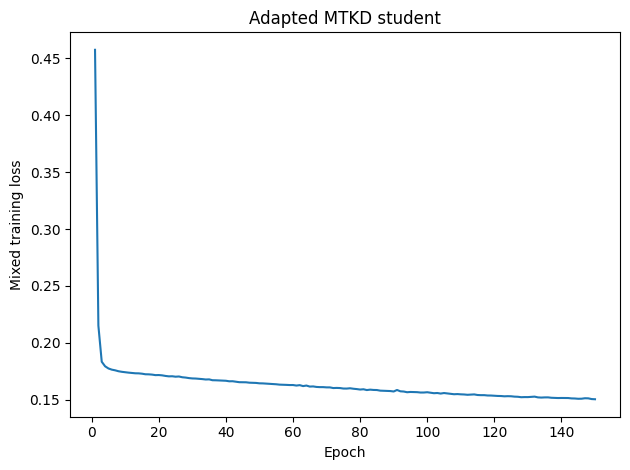

In [24]:
set_seed(SEED + 40)
student = make_network(input_size, 32, 16)
student_initial_weights = copy.deepcopy(student.state_dict())

student_data = TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                             torch.tensor(y_train, dtype=torch.long),
                             soft_targets)

student_batches = DataLoader(student_data, batch_size=BATCH_SIZE, shuffle=True)

optimizer = torch.optim.Adam(student.parameters(), lr=LEARNING_RATE,
                             weight_decay=WEIGHT_DECAY)

student_losses = []
student_history = []

# Reset the training seed so the labels-only control uses identical batch order.
set_seed(SEED + 40)
student_progress = tqdm(range(EPOCHS), desc='Adapted MTKD student', unit='epoch')

for epoch in student_progress:
    student.train()
    total_loss = 0

    for batch_inputs, batch_labels, batch_targets in student_batches:
        batch_inputs = batch_inputs.to(device)
        batch_labels = batch_labels.to(device)
        batch_targets = batch_targets.to(device)

        scores = student(batch_inputs)
        label_loss = F.cross_entropy(scores, batch_labels)

        soft_loss = F.kl_div(F.log_softmax(scores / TEMPERATURE, dim=1),
                            batch_targets, reduction='batchmean')
        soft_loss = soft_loss * TEMPERATURE ** 2

        loss = LABEL_WEIGHT * label_loss + (1 - LABEL_WEIGHT) * soft_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_labels)

    average_loss = total_loss / len(student_data)
    student_losses.append(average_loss)

    row = monitor_epoch(student, 'Adapted MTKD student', epoch + 1, average_loss,
                        (X_val, y_val), (X_test, y_test), EPOCHS)
    student_history.append(row)

    if (epoch + 1) % LOG_EVERY == 0 or epoch + 1 == EPOCHS:
        student_progress.set_postfix(val_AP=f"{row['val_AP']:.3f}",
                                     test_AP=f"{row['test_AP']:.3f}")

save_training_run(student, 'Adapted MTKD student', student_history,
                  (X_val, y_val), (X_test, y_test))

mtkd_seconds = time.perf_counter() - mtkd_start

plt.plot(range(1, EPOCHS + 1), student_losses)
plt.xlabel('Epoch')
plt.ylabel('Mixed training loss')
plt.title('Adapted MTKD student')
plt.tight_layout()
plt.show()


### Step 4: train the labels-only student control
Same small architecture, original values, epochs, and batch order. Only the loss changes. This gives a clearer test of whether distillation helps.


**Code cell 25 — Train the labels-only student**

Restores the same small student’s original values and trains it using only true labels, with the same epoch budget and batch order.

**Output:** A progress bar and score history for the control. Comparing it with MTKD helps show whether distillation improved the small network.


In [25]:
label_student = make_network(input_size, 32, 16)
label_student.load_state_dict(student_initial_weights)

set_seed(SEED + 40)
label_student_losses = train_network(label_student, X_train, y_train, EPOCHS,
                                       run_name='Labels-only student')


Labels-only student:   0%|          | 0/150 [00:00<?, ?epoch/s]

Labels-only student | Epoch 010 | Train loss 0.3155 | Val: loss 0.3377, acc 0.8788, F1 0.0762, AP 0.3057 | Test: loss 0.3411, acc 0.8720, F1 0.0857, AP 0.2770
Labels-only student | Epoch 020 | Train loss 0.3106 | Val: loss 0.3408, acc 0.8738, F1 0.1062, AP 0.2958 | Test: loss 0.3444, acc 0.8700, F1 0.0972, AP 0.2740
Labels-only student | Epoch 030 | Train loss 0.3040 | Val: loss 0.3463, acc 0.8738, F1 0.1217, AP 0.2872 | Test: loss 0.3497, acc 0.8720, F1 0.1351, AP 0.2701
Labels-only student | Epoch 040 | Train loss 0.2964 | Val: loss 0.3481, acc 0.8688, F1 0.2222, AP 0.2841 | Test: loss 0.3556, acc 0.8610, F1 0.1677, AP 0.2639
Labels-only student | Epoch 050 | Train loss 0.2880 | Val: loss 0.3520, acc 0.8675, F1 0.1719, AP 0.2803 | Test: loss 0.3606, acc 0.8570, F1 0.1637, AP 0.2530
Labels-only student | Epoch 060 | Train loss 0.2792 | Val: loss 0.3622, acc 0.8675, F1 0.2639, AP 0.2810 | Test: loss 0.3759, acc 0.8490, F1 0.1925, AP 0.2453
Labels-only student | Epoch 070 | Train loss 0

## 8. Method 3 — XGBoost
XGBoost builds trees in sequence. Later trees correct errors in the current prediction. Trees can learn feature interactions without a neural architecture. This makes them a useful tabular comparison; better results are not guaranteed.

| Hyperparameter | Fixed value | Why we choose it |
|---|---|---|
| n_estimators | 400 | A bounded number of boosting steps |
| learning_rate | 0.05 | Small contributions per tree; paired with 400 steps |
| max_depth | 3 | Shallow interactions to limit memorization on a small dataset |
| min_child_weight | 5 | Discourages weakly supported splits; this is a Hessian-weight threshold, not five employees |
| subsample | 0.8 | Randomly uses part of the rows per tree |
| colsample_bytree | 0.8 | Randomly uses part of the encoded features per tree |
| reg_lambda | 1.0 | L2 penalty on leaf weights |
| reg_alpha | 0.0 | No extra L1 penalty in this baseline |
| gamma | 0.0 | No added minimum split-loss penalty; depth and child weight already constrain trees |
| scale_pos_weight | 1.0 | Same unweighted label objective as neural methods; avoids intentionally shifting class costs |
| objective | binary:logistic | Produces a binary-class probability |
| eval_metric | logloss, error, aucpr | Tracks probability error, classification error, and precision–recall ranking |
| tree_method | hist | Uses histogram-based tree construction |
| n_jobs | 2 | Limits CPU resource use |
| random_state | 42 | Repeatable sampling |

Exact values are experiment choices. Parameter meanings are described in the [official XGBoost documentation](https://xgboost.readthedocs.io/en/stable/parameter.html). Train, validation and test metrics are recorded every boosting round, with tqdm progress and printed score messages every 10 rounds without early stopping; all 400 trees are retained. `error` is the misclassification rate, so accuracy = 1 − error. `aucpr` is XGBoost’s native PR-AUC; it is not identical to scikit-learn average precision (AP). Final comparisons still use the same AP definition for all methods. See the [official Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html).


**Code cell 26 — Train and monitor XGBoost**

Defines a small callback that updates tqdm during XGBoost’s internal training loop. Trains 400 rounds and prints loss, accuracy, and native PR-AUC every 10 rounds. The callback returns False so training continues.

**Output:** A progress bar, score messages, a full per-round table, and three curves. XGBoost PR-AUC differs from the AP used in final comparisons.


XGBoost:   0%|          | 0/400 [00:00<?, ?round/s]

XGBoost | Round 010 | Train loss 0.3389 | Val: loss 0.3457, acc 0.8775, PR-AUC 0.2902 | Test: loss 0.3483, acc 0.8770, PR-AUC 0.2974
XGBoost | Round 020 | Train loss 0.3240 | Val: loss 0.3365, acc 0.8775, PR-AUC 0.2998 | Test: loss 0.3390, acc 0.8770, PR-AUC 0.2989
XGBoost | Round 030 | Train loss 0.3161 | Val: loss 0.3338, acc 0.8800, PR-AUC 0.3019 | Test: loss 0.3362, acc 0.8790, PR-AUC 0.3007
XGBoost | Round 040 | Train loss 0.3109 | Val: loss 0.3326, acc 0.8788, PR-AUC 0.3011 | Test: loss 0.3360, acc 0.8800, PR-AUC 0.2994
XGBoost | Round 050 | Train loss 0.3073 | Val: loss 0.3327, acc 0.8788, PR-AUC 0.2998 | Test: loss 0.3361, acc 0.8780, PR-AUC 0.2974
XGBoost | Round 060 | Train loss 0.3041 | Val: loss 0.3339, acc 0.8762, PR-AUC 0.3023 | Test: loss 0.3375, acc 0.8800, PR-AUC 0.2948
XGBoost | Round 070 | Train loss 0.3017 | Val: loss 0.3352, acc 0.8738, PR-AUC 0.3029 | Test: loss 0.3386, acc 0.8770, PR-AUC 0.2943
XGBoost | Round 080 | Train loss 0.2995 | Val: loss 0.3370, acc 0.873

,round,train_logloss,train_accuracy,train_PR_AUC,val_logloss,val_accuracy,val_PR_AUC,test_logloss,test_accuracy,test_PR_AUC
0,1,0.3667,0.8775,0.3140,0.3675,0.8775,0.2701,0.3684,0.877,0.2656
1,2,0.3623,0.8775,0.3322,0.3638,0.8775,0.2748,0.3652,0.877,0.2588
2,3,0.3584,0.8775,0.3415,0.3608,0.8775,0.2807,0.3626,0.877,0.2564
3,4,0.3551,0.8775,0.3414,0.3578,0.8775,0.2832,0.3601,0.877,0.2587
4,5,0.3518,0.8775,0.3479,0.3551,0.8775,0.2786,0.3579,0.877,0.2686
...,...,...,...,...,...,...,...,...,...,...
395,396,0.2562,0.8962,0.5898,0.3633,0.8688,0.2554,0.3578,0.875,0.2761
396,397,0.2561,0.8962,0.5895,0.3633,0.8688,0.2556,0.3579,0.874,0.2763
397,398,0.2561,0.8962,0.5894,0.3635,0.8688,0.2554,0.3580,0.874,0.2761
398,399,0.2560,0.8962,0.5902,0.3638,0.8688,0.2548,0.3580,0.875,0.2760


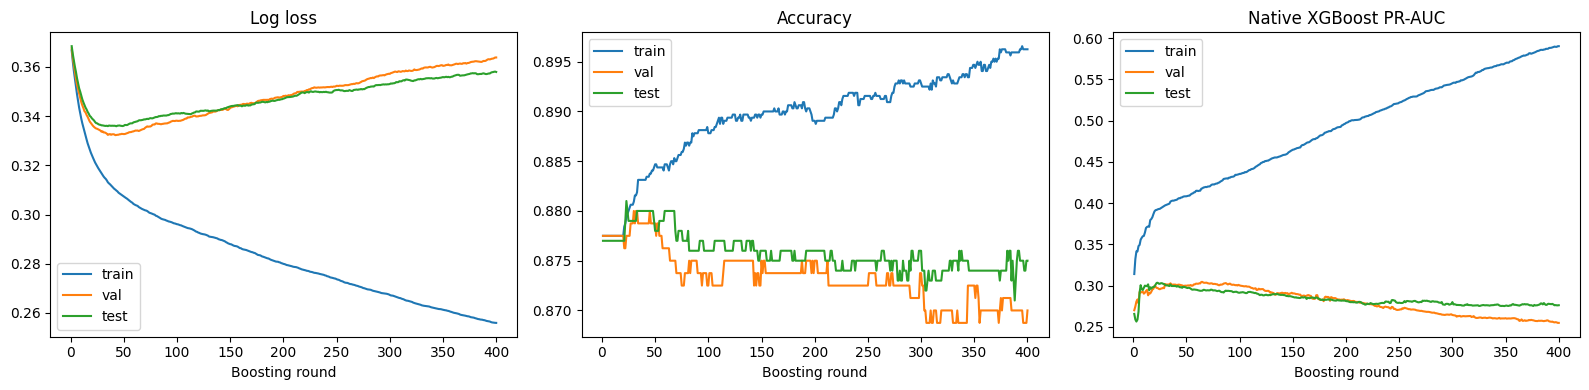

In [26]:
# XGBoost trains inside its own fit() call, so a callback updates tqdm.
class TqdmBoostingProgress(TrainingCallback):
    def __init__(self, total_rounds):
        self.total_rounds = total_rounds

    def before_training(self, model):
        self.progress = tqdm(total=self.total_rounds, desc='XGBoost', unit='round')
        return model

    def after_iteration(self, model, epoch, evals_log):
        self.progress.update(1)
        round_number = epoch + 1

        if round_number % LOG_EVERY == 0 or round_number == self.total_rounds:
            train_metrics = evals_log['validation_0']
            val_metrics = evals_log['validation_1']
            test_metrics = evals_log['validation_2']

            val_accuracy = 1 - val_metrics['error'][-1]
            test_accuracy = 1 - test_metrics['error'][-1]

            self.progress.set_postfix(val_PR_AUC=f"{val_metrics['aucpr'][-1]:.3f}",
                                      test_PR_AUC=f"{test_metrics['aucpr'][-1]:.3f}")

            tqdm.write(
                f"XGBoost | Round {round_number:03d} | "
                f"Train loss {train_metrics['logloss'][-1]:.4f} | "
                f"Val: loss {val_metrics['logloss'][-1]:.4f}, acc {val_accuracy:.4f}, "
                f"PR-AUC {val_metrics['aucpr'][-1]:.4f} | "
                f"Test: loss {test_metrics['logloss'][-1]:.4f}, acc {test_accuracy:.4f}, "
                f"PR-AUC {test_metrics['aucpr'][-1]:.4f}"
            )

        return False  # Continue training; this callback does not select an epoch.

    def after_training(self, model):
        self.progress.close()
        return model

xgb_start = time.perf_counter()
xgb = XGBClassifier(
    n_estimators=BOOSTING_ROUNDS,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.0,
    gamma=0.0,
    scale_pos_weight=1.0,
    objective='binary:logistic',
    eval_metric=['logloss', 'error', 'aucpr'],
    tree_method='hist',
    callbacks=[TqdmBoostingProgress(BOOSTING_ROUNDS)],
    n_jobs=2,
    random_state=SEED
)

# validation_0 = train, validation_1 = validation, validation_2 = test.
# These evaluation datasets do not supply training gradients.
xgb.fit(
    X_train_tree, y_train,
    eval_set=[(X_train_tree, y_train), (X_val_tree, y_val), (X_test_tree, y_test)],
    verbose=False
)

xgb_seconds = time.perf_counter() - xgb_start
history = xgb.evals_result()

xgb_epoch_history = pd.DataFrame({'round': range(1, BOOSTING_ROUNDS + 1)})

for split_name, dataset_name in [('train', 'validation_0'),
                                 ('val', 'validation_1'),
                                 ('test', 'validation_2')]:
    xgb_epoch_history[split_name + '_logloss'] = history[dataset_name]['logloss']
    xgb_epoch_history[split_name + '_accuracy'] = 1 - np.array(history[dataset_name]['error'])
    xgb_epoch_history[split_name + '_PR_AUC'] = history[dataset_name]['aucpr']

print('Full XGBoost history: accuracy = 1 - error')
display(xgb_epoch_history.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for split_name in ['train', 'val', 'test']:
    axes[0].plot(xgb_epoch_history['round'], xgb_epoch_history[split_name + '_logloss'], label=split_name)
    axes[1].plot(xgb_epoch_history['round'], xgb_epoch_history[split_name + '_accuracy'], label=split_name)
    axes[2].plot(xgb_epoch_history['round'], xgb_epoch_history[split_name + '_PR_AUC'], label=split_name)

for ax, title in zip(axes, ['Log loss', 'Accuracy', 'Native XGBoost PR-AUC']):
    ax.set_title(title)
    ax.set_xlabel('Boosting round')
    ax.legend()

plt.tight_layout()
plt.show()


### Learning curves and final confusion matrices for each neural run

Each LTH round has its own curve and final matrix. This lets you inspect both training progress and the effect of pruning.


**Code cell 27 — Review histories and confusion matrices**

Reads stored histories for every main neural run, including each LTH round. Plots loss, accuracy, F1, and AP, followed by final validation/test confusion matrices. OOF plots are optional.

**Output:** Final score rows, learning curves, and matrices. Every epoch remains in the curves even though text logs appear only every 10 epochs.


Dense baseline — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
149,150,0.1451,0.84,0.823,0.1688,0.1843,0.2019,0.1907,0.588,0.6474


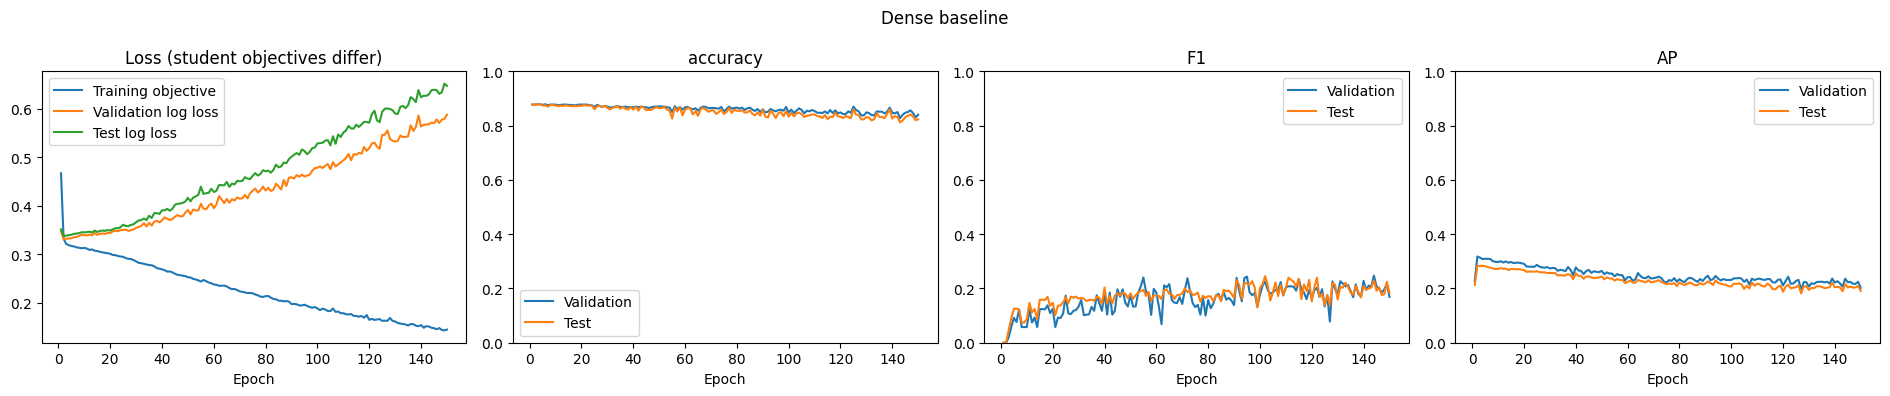

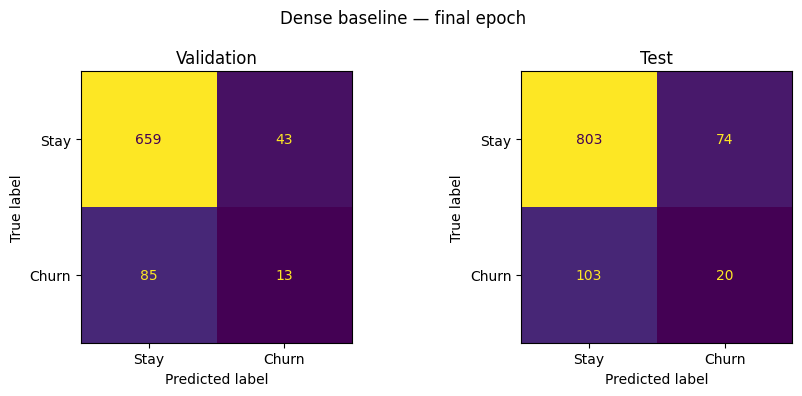

LTH round 1 — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
149,150,0.1559,0.8338,0.832,0.2036,0.2075,0.2069,0.2085,0.6011,0.6138


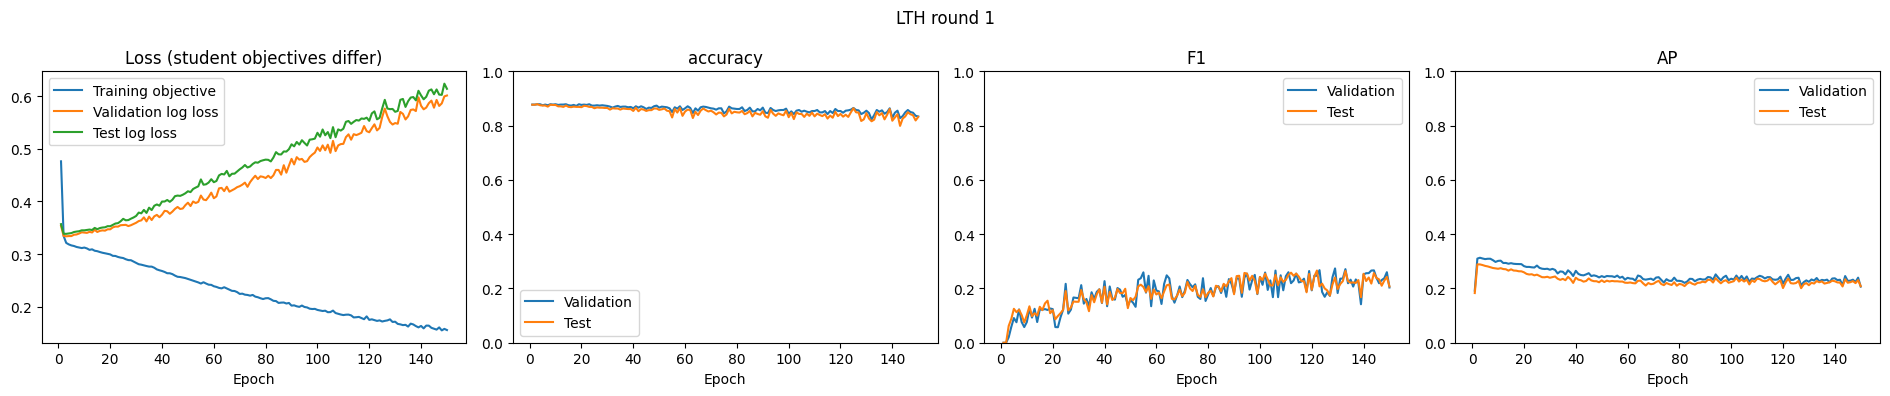

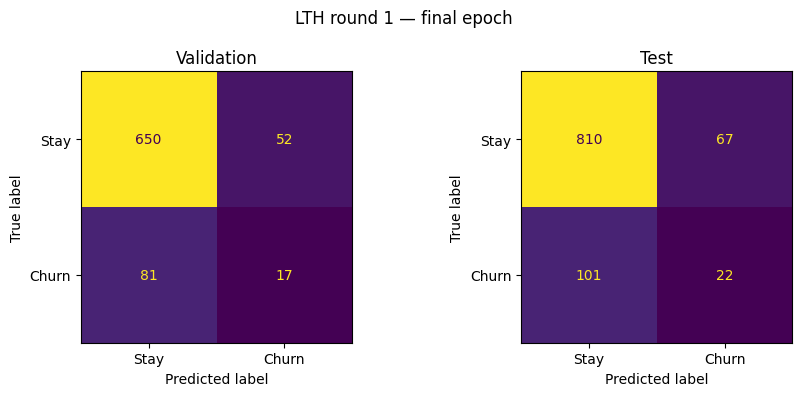

LTH round 2 — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
149,150,0.1875,0.855,0.835,0.1831,0.1709,0.2077,0.2046,0.5468,0.5458


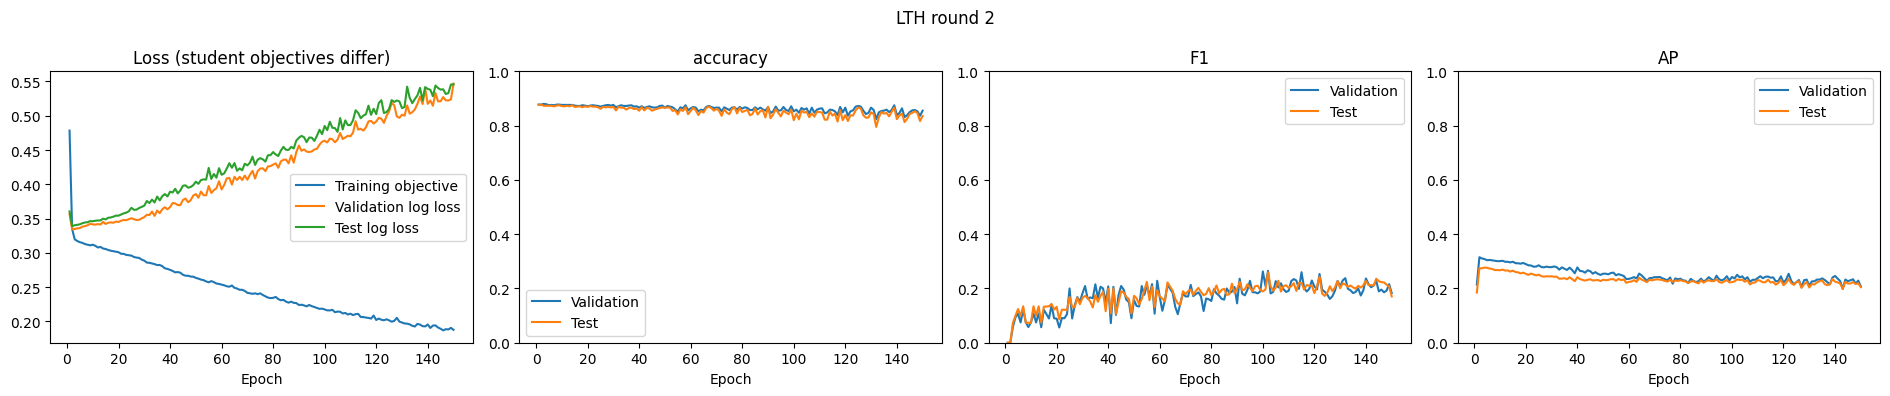

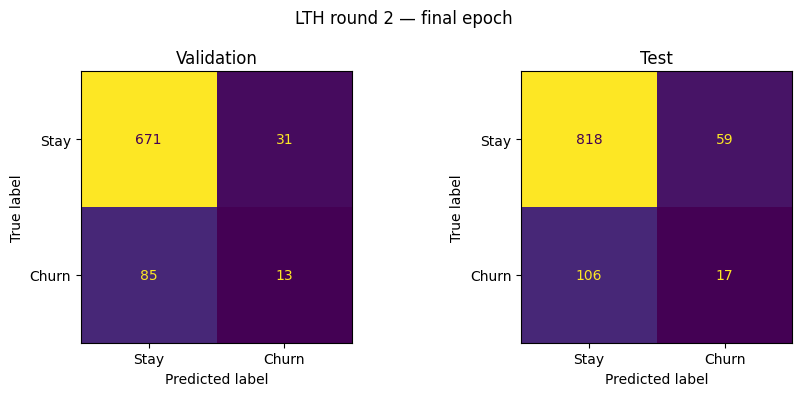

LTH round 3 — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
149,150,0.1936,0.8362,0.825,0.1438,0.2009,0.2102,0.1909,0.5237,0.5446


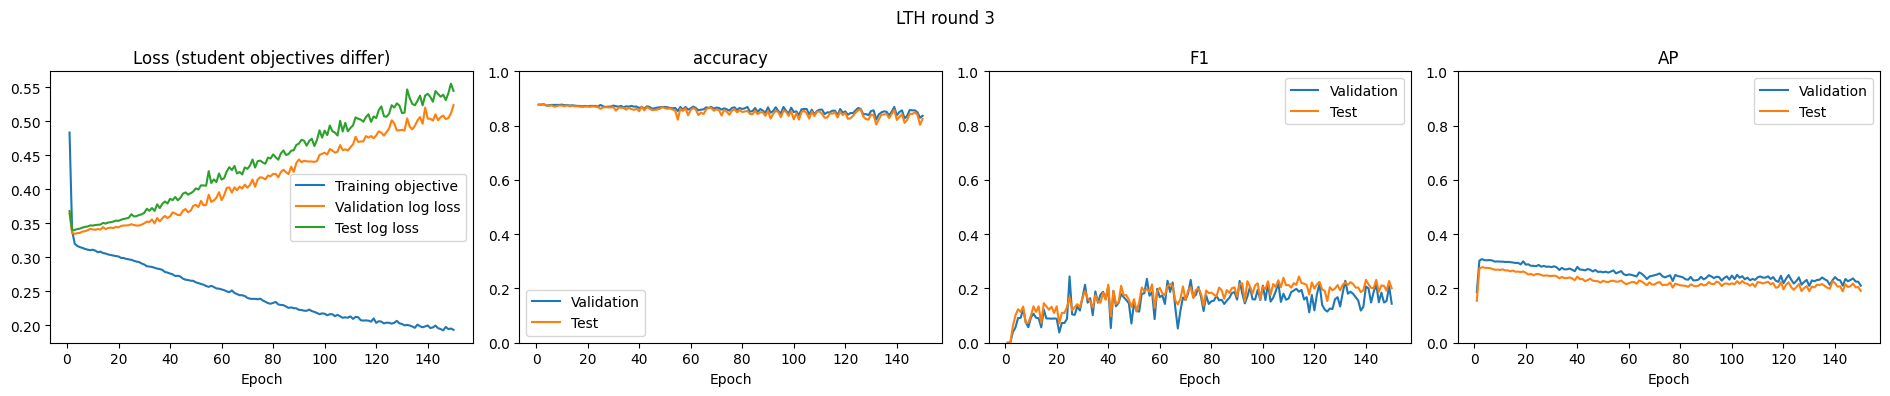

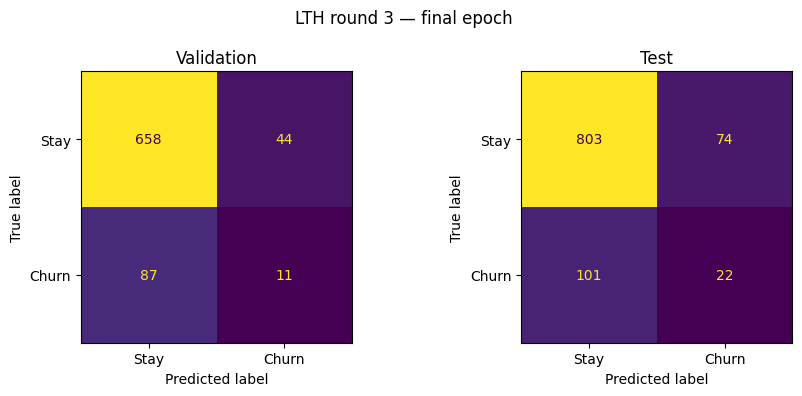

LTH round 4 — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
149,150,0.2082,0.8488,0.834,0.1769,0.1942,0.2212,0.1867,0.4998,0.5247


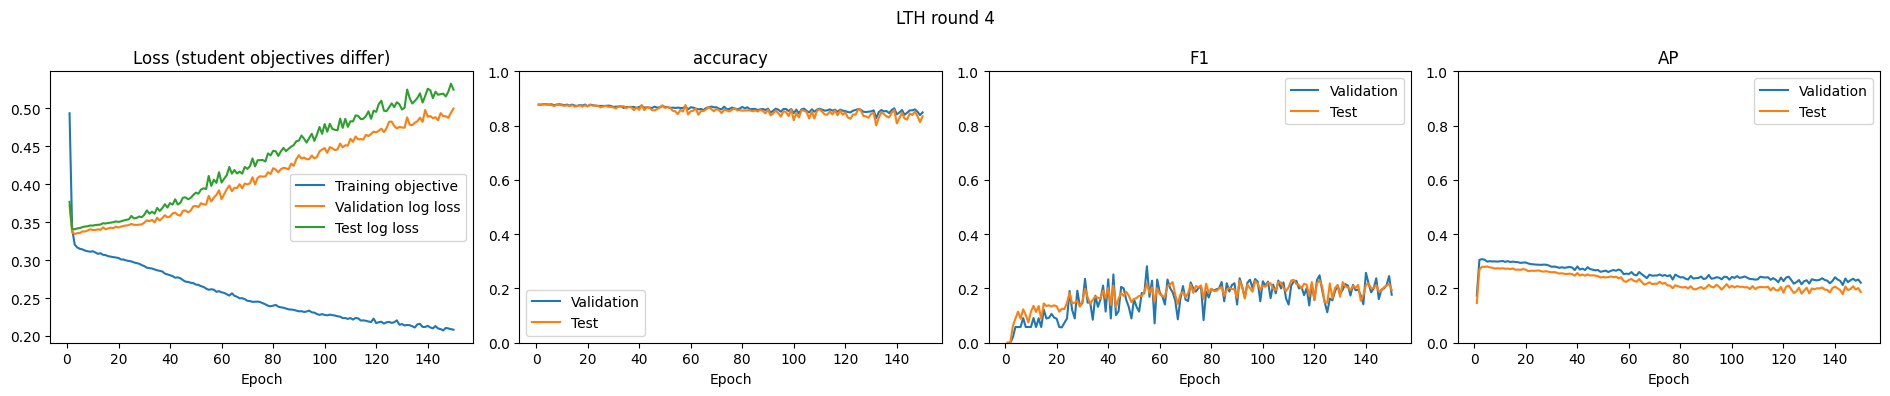

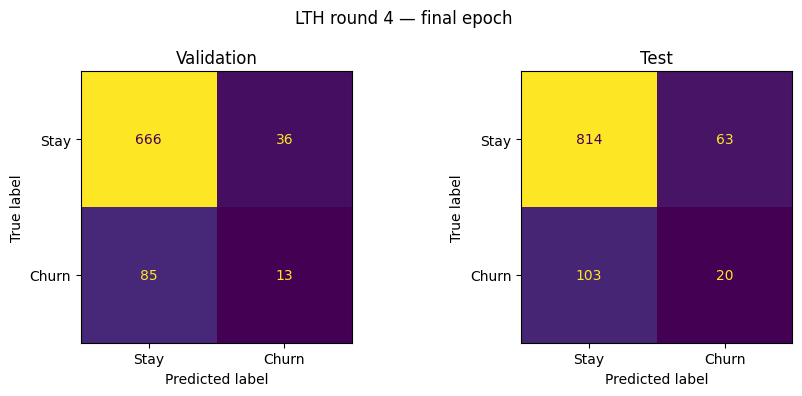

LTH round 5 — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
149,150,0.2201,0.8525,0.843,0.169,0.2266,0.2313,0.206,0.4618,0.4886


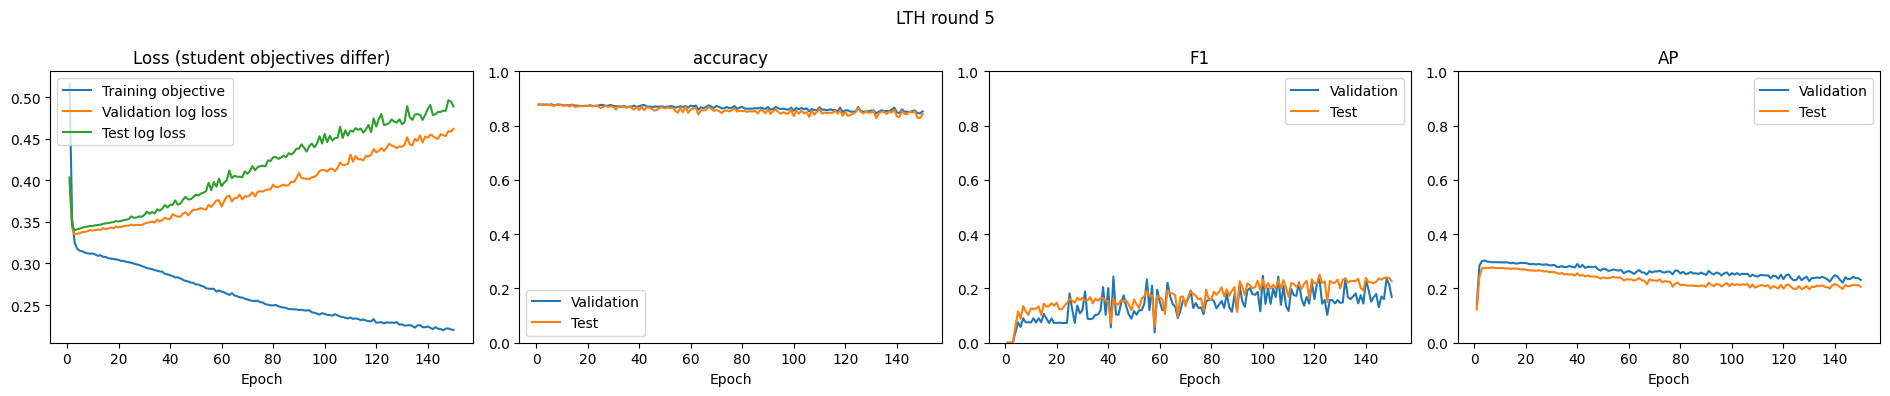

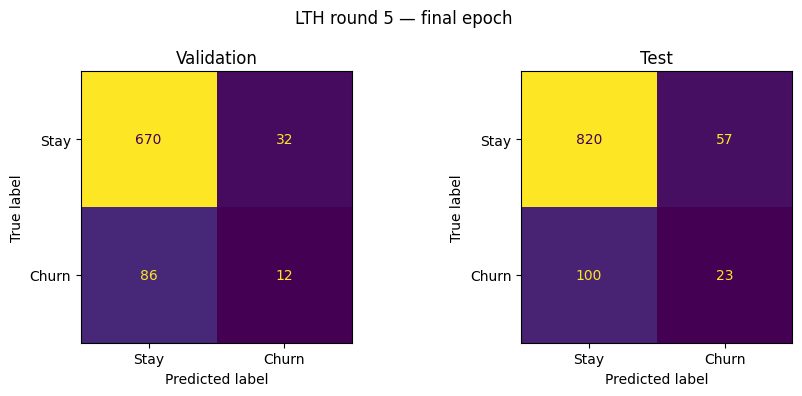

LTH random initialization — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
149,150,0.2562,0.8662,0.858,0.2074,0.1647,0.2567,0.233,0.4026,0.4162


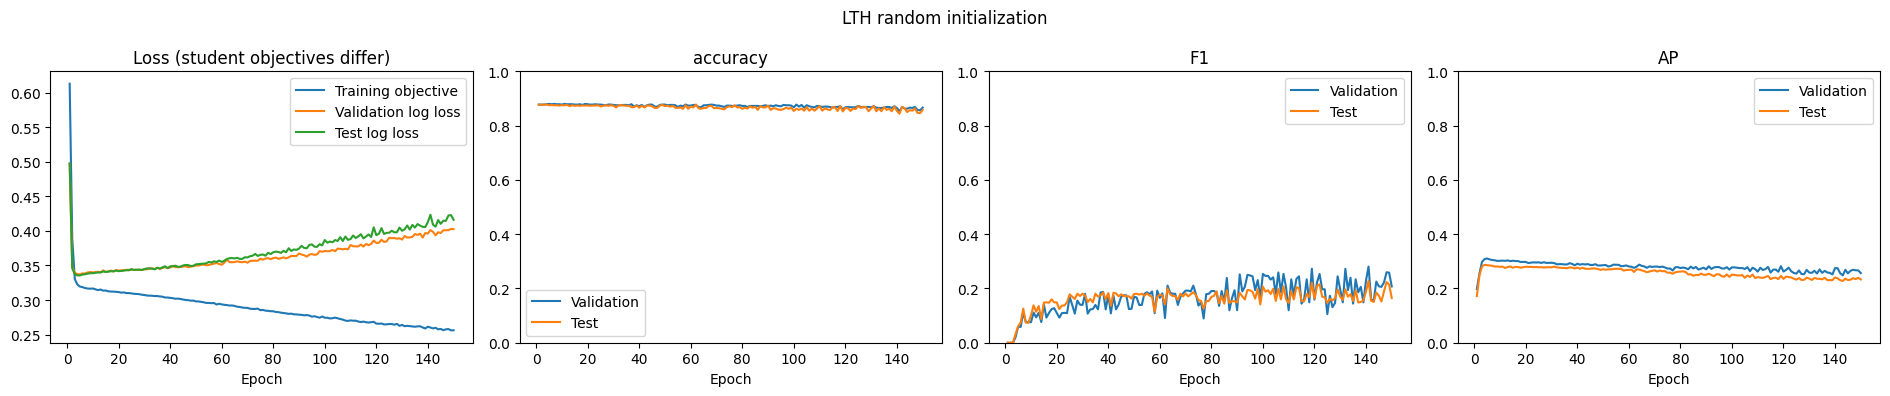

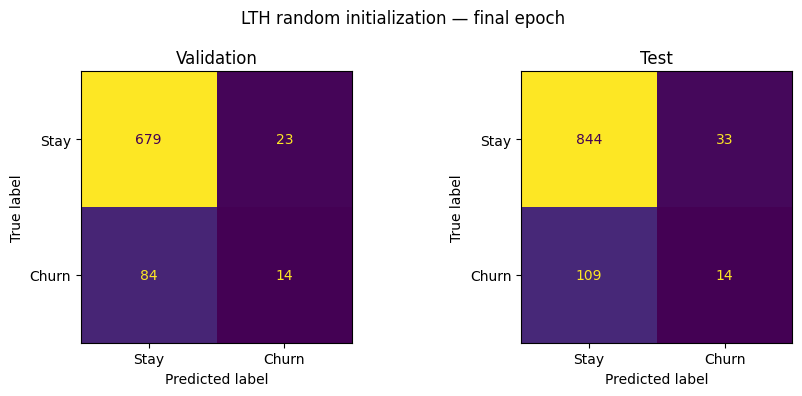

Full teacher 1 — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
99,100,0.1048,0.8362,0.832,0.1438,0.2075,0.2032,0.2206,0.7021,0.7177


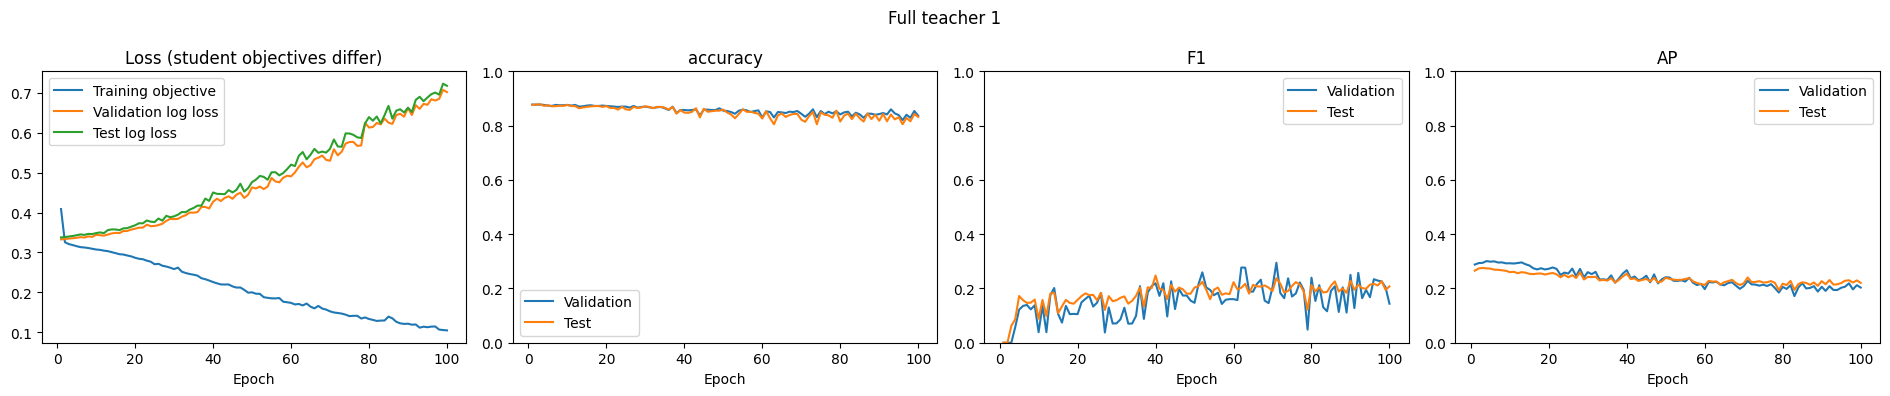

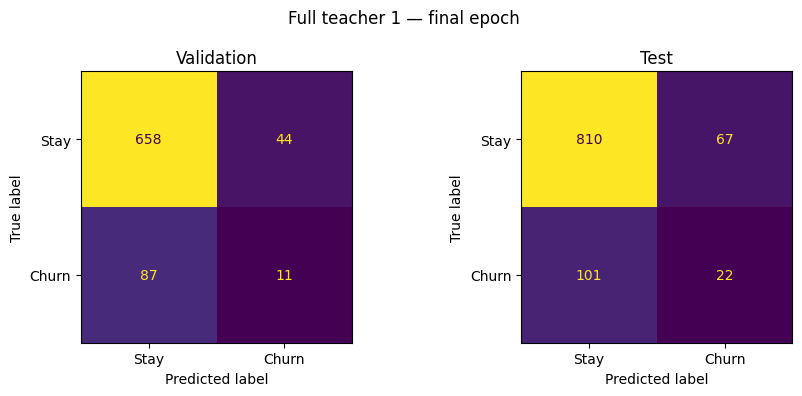

Full teacher 2 — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
99,100,0.1812,0.8438,0.829,0.2424,0.24,0.243,0.2359,0.5279,0.5387


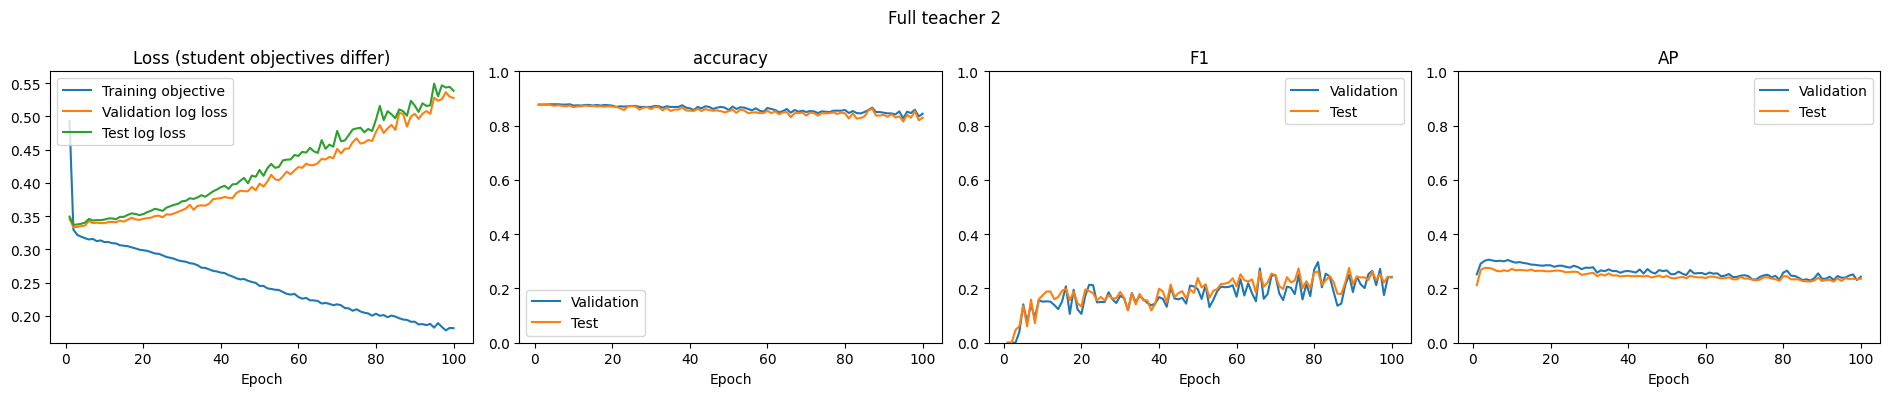

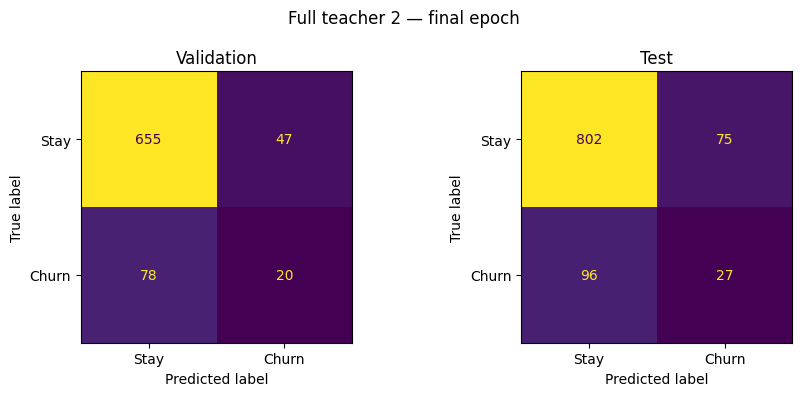

Full teacher 3 — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
99,100,0.1299,0.8462,0.835,0.1277,0.1791,0.1972,0.1896,0.6741,0.6966


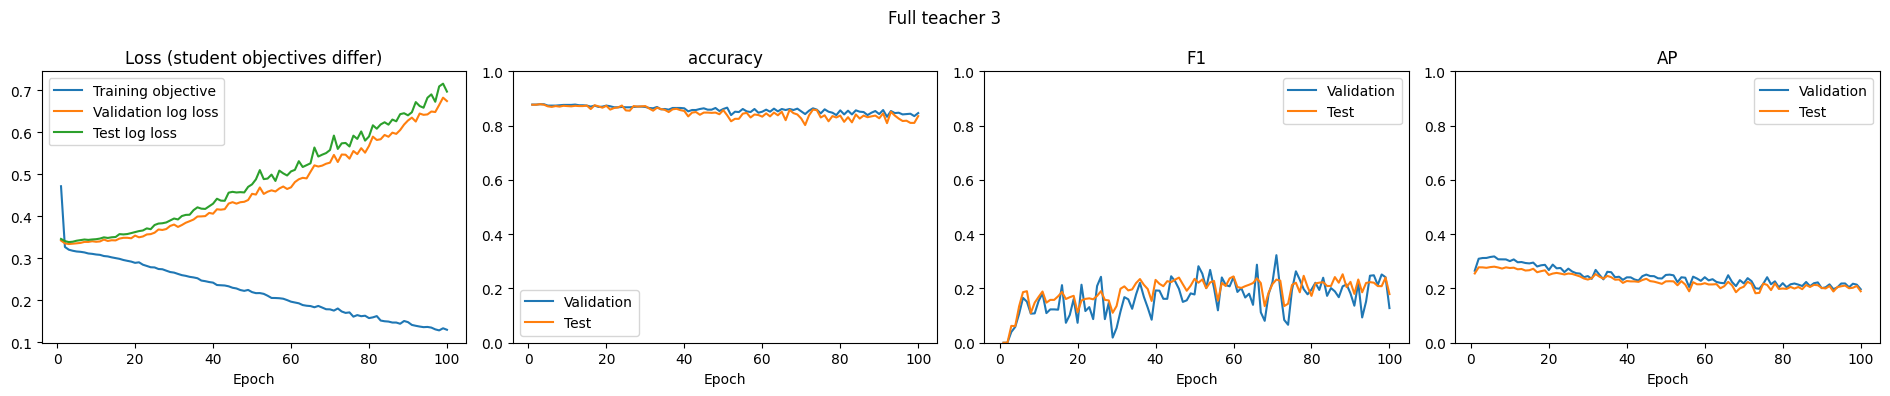

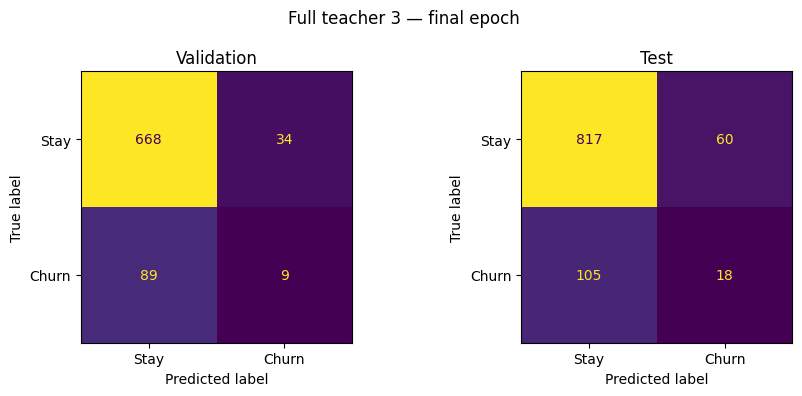

Adapted MTKD student — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
149,150,0.1503,0.8738,0.874,0.0734,0.137,0.2571,0.2292,0.3541,0.3667


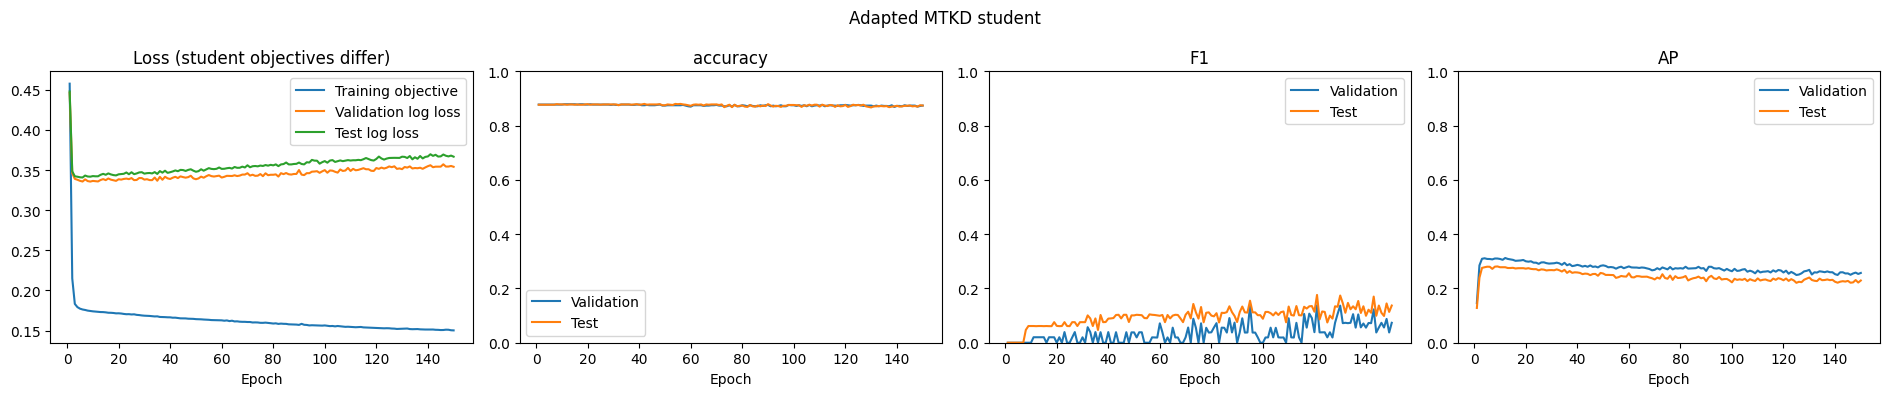

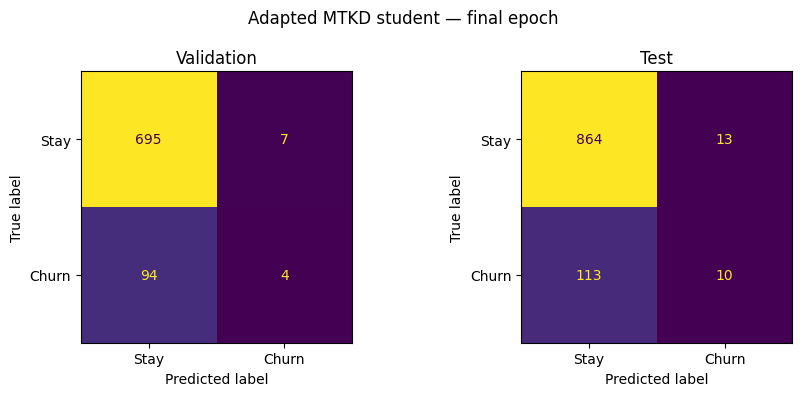

Labels-only student — final epoch metrics


,epoch,training_loss,val_accuracy,test_accuracy,val_F1,test_F1,val_AP,test_AP,val_logloss,test_logloss
149,150,0.2222,0.8612,0.849,0.1527,0.1749,0.2264,0.1964,0.4425,0.4634


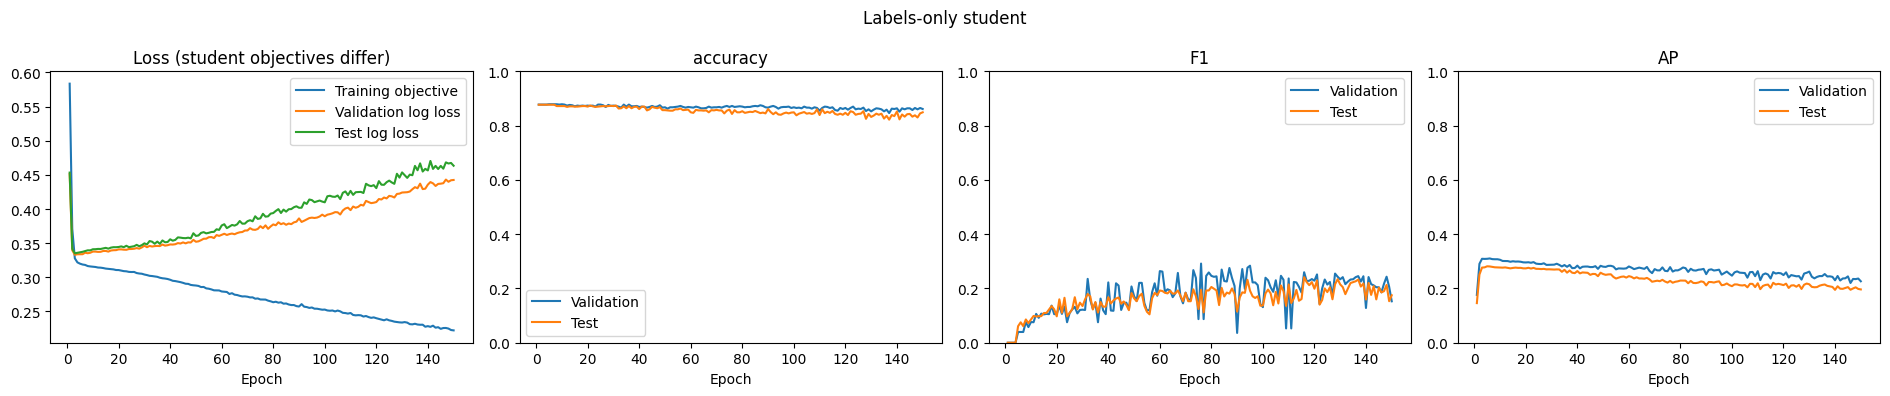

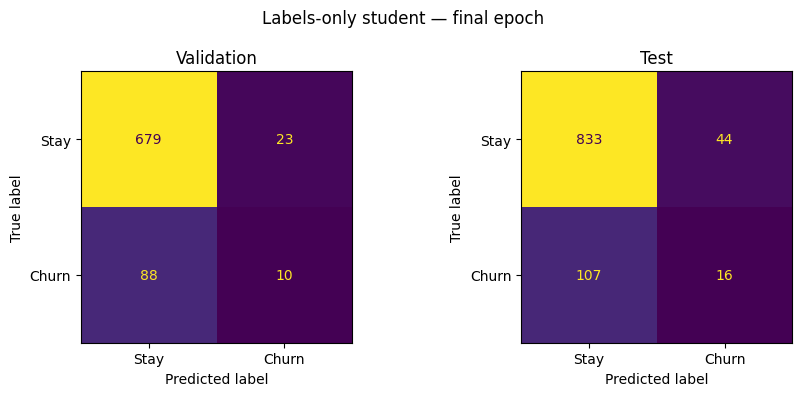

In [27]:
# Main training runs: dense baseline, each LTH round, random initialization,
# full teachers, distilled student, and labels-only student.
for run_name, run in training_runs.items():
    if run_name.startswith('OOF') and not SHOW_FOLD_PLOTS:
        continue

    scores = run['history']
    print(run_name, '— final epoch metrics')
    display(scores.tail(1).round(4))

    fig, axes = plt.subplots(1, 4, figsize=(19, 4))
    axes[0].plot(scores['epoch'], scores['training_loss'], label='Training objective')
    axes[0].plot(scores['epoch'], scores['val_logloss'], label='Validation log loss')
    axes[0].plot(scores['epoch'], scores['test_logloss'], label='Test log loss')
    axes[0].set_title('Loss (student objectives differ)')

    for ax, metric in zip(axes[1:], ['accuracy', 'F1', 'AP']):
        ax.plot(scores['epoch'], scores['val_' + metric], label='Validation')
        ax.plot(scores['epoch'], scores['test_' + metric], label='Test')
        ax.set_title(metric)
        ax.set_ylim(0, 1)

    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.legend()

    fig.suptitle(run_name)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(9, 4))

    for ax, split in zip(axes, ['val', 'test']):
        probabilities = run[split + '_probabilities']
        labels = run[split + '_labels']
        predictions = (probabilities >= THRESHOLD).astype(int)

        ConfusionMatrixDisplay.from_predictions(
            labels, predictions, labels=[0, 1], display_labels=['Stay', 'Churn'],
            colorbar=False, ax=ax
        )
        ax.set_title('Validation' if split == 'val' else 'Test')

    fig.suptitle(run_name + ' — final epoch')
    plt.tight_layout()
    plt.show()
    plt.close(fig)


## 9. Validation comparison at the fixed final epoch
**Primary comparison metric: average precision (AP)**, a summary of the precision–recall curve. This is useful when churn is uncommon because it focuses on the positive class. A random ranking has expected AP near the positive share. We also report ROC-AUC, which compares ranking across both classes.

| Metric | Meaning |
|---|---|
| Accuracy | Share of all labels predicted correctly; can hide missed churn |
| Precision | Among employees predicted to churn, the share who actually churn |
| Recall | Among actual churn employees, the share the model finds |
| F1 | Balance of precision and recall at the fixed 0.5 threshold |
| ROC-AUC | Ranking ability across false-positive and true-positive rates |
| AP | Precision–recall ranking summary; higher is better |
| Log loss | Penalty for wrong probability predictions, especially confident errors; lower is better |

We compare the three requested outputs and keep controls separate. The always-stay dummy exposes the accuracy trap. The aggregation model is a teacher system, not the deployable MTKD student. A weak teacher system can give the student little useful knowledge.


### One small evaluation function
The function takes actual labels and churn probabilities. It converts probabilities to labels using the same 0.5 threshold, then returns the metrics. Slice `[:, 1]` means **all rows, the churn-probability column**.


**Code cell 28 — Compare final validation performance**

Defines the final evaluation function and calculates the three methods’ validation metrics plus control scores. The recommended method is the one with the highest final validation AP.

**Output:** Validation comparison tables and the recommendation. Test scores do not choose the method.


In [28]:
def evaluate(actual_labels, churn_probabilities):
    predicted_labels = (churn_probabilities >= THRESHOLD).astype(int)

    return {
        'Accuracy': accuracy_score(actual_labels, predicted_labels),
        'Precision': precision_score(actual_labels, predicted_labels, zero_division=0),
        'Recall': recall_score(actual_labels, predicted_labels, zero_division=0),
        'F1': f1_score(actual_labels, predicted_labels, zero_division=0),
        'ROC-AUC': roc_auc_score(actual_labels, churn_probabilities),
        'AP': average_precision_score(actual_labels, churn_probabilities),
        'Log loss': log_loss(actual_labels, churn_probabilities, labels=[0, 1])
    }

# Main methods: explicit predictions make each step easy to follow.
val_lth = predict(lth_model, X_val)[:, 1]
val_mtkd = predict(student, X_val)[:, 1]
val_xgb = xgb.predict_proba(X_val_tree)[:, 1]

validation_results = pd.DataFrame({
    'LTH': evaluate(y_val, val_lth),
    'Adapted MTKD': evaluate(y_val, val_mtkd),
    'XGBoost': evaluate(y_val, val_xgb)
}).T

display(validation_results.round(4))

recommended_method = validation_results['AP'].idxmax()
print('Validation recommendation by AP:', recommended_method)

# Controls: see what pruning and distillation changed.
validation_controls = pd.DataFrame({
    'Dense baseline': evaluate(y_val, predict(dense_model, X_val)[:, 1]),
    'Same-mask random initialization': evaluate(y_val, predict(random_ticket, X_val)[:, 1]),
    'Labels-only student': evaluate(y_val, predict(label_student, X_val)[:, 1]),
    'Always-stay baseline': evaluate(y_val, np.zeros(len(y_val)))
}).T

display(validation_controls.round(4))


,Accuracy,Precision,Recall,F1,ROC-AUC,AP,Log loss
LTH,0.8525,0.2727,0.1224,0.1690,0.6885,0.2313,0.4618
Adapted MTKD,0.8738,0.3636,0.0408,0.0734,0.6443,0.2571,0.3541
XGBoost,0.8700,0.3750,0.0918,0.1475,0.6885,0.2588,0.3638


Validation recommendation by AP: XGBoost


,Accuracy,Precision,Recall,F1,ROC-AUC,AP,Log loss
Dense baseline,0.8400,0.2321,0.1327,0.1688,0.6755,0.2019,0.5880
Same-mask random initialization,0.8662,0.3784,0.1429,0.2074,0.6984,0.2567,0.4026
Labels-only student,0.8612,0.3030,0.1020,0.1527,0.6726,0.2264,0.4425
Always-stay baseline,0.8775,0.0000,0.0000,0.0000,0.5000,0.1225,4.4153


## 10. Fixed-final-model test comparison
All methods see the same test employees. This makes the comparison meaningful, but it does not equalize training computation: LTH repeatedly retrains a model and MTKD trains many teachers. Test performance cannot decide new hyperparameters in this experiment.

A method can have good ranking scores and low recall at 0.5. That means ranking and threshold decisions tell different stories. Look at the confusion matrix: **false negatives** are missed churn cases; **false positives** are stayers wrongly flagged. Whether each error is costly depends on the intended support action.


**Code cell 29 — Compare final test performance**

Uses the final trained models to predict the common test employees, then applies the same evaluation function to methods and controls.

**Output:** Test accuracy, precision, recall, F1, ROC-AUC, AP, and log loss. These are monitoring results because the test set was visible during training.


In [29]:
test_lth = predict(lth_model, X_test)[:, 1]
test_mtkd = predict(student, X_test)[:, 1]
test_xgb = xgb.predict_proba(X_test_tree)[:, 1]

test_results = pd.DataFrame({
    'LTH': evaluate(y_test, test_lth),
    'Adapted MTKD': evaluate(y_test, test_mtkd),
    'XGBoost': evaluate(y_test, test_xgb)
}).T

display(test_results.round(4))

test_controls = pd.DataFrame({
    'Dense baseline': evaluate(y_test, predict(dense_model, X_test)[:, 1]),
    'Same-mask random initialization': evaluate(y_test, predict(random_ticket, X_test)[:, 1]),
    'Labels-only student': evaluate(y_test, predict(label_student, X_test)[:, 1]),
    'Always-stay baseline': evaluate(y_test, np.zeros(len(y_test)))
}).T

display(test_controls.round(4))


,Accuracy,Precision,Recall,F1,ROC-AUC,AP,Log loss
LTH,0.843,0.2875,0.1870,0.2266,0.6324,0.2060,0.4886
Adapted MTKD,0.874,0.4348,0.0813,0.1370,0.6326,0.2292,0.3667
XGBoost,0.875,0.4667,0.1138,0.1830,0.6983,0.2791,0.3579


,Accuracy,Precision,Recall,F1,ROC-AUC,AP,Log loss
Dense baseline,0.823,0.2128,0.1626,0.1843,0.6350,0.1907,0.6474
Same-mask random initialization,0.858,0.2979,0.1138,0.1647,0.6595,0.2330,0.4162
Labels-only student,0.849,0.2667,0.1301,0.1749,0.6384,0.1964,0.4634
Always-stay baseline,0.877,0.0000,0.0000,0.0000,0.5000,0.1230,4.4334


### Compare teacher quality
The aggregation system is a useful diagnostic, but the small student is the MTKD output we compare with LTH and XGBoost. Teachers remain frozen.


**Code cell 30 — Check teachers and their aggregation**

Collects all three teachers’ validation/test predictions, combines them with the learned aggregator, and reports final teacher-system test scores.

**Output:** Teacher and aggregation-system metrics. These diagnose the knowledge source; the small student remains the MTKD comparison model.


In [30]:
val_teacher_predictions = np.column_stack([predict(teacher, X_val)[:, 1] for teacher in teachers])
test_teacher_predictions = np.column_stack([predict(teacher, X_test)[:, 1] for teacher in teachers])

val_aggregated = aggregator.predict_proba(val_teacher_predictions)[:, 1]
test_aggregated = aggregator.predict_proba(test_teacher_predictions)[:, 1]

teacher_scores = {}

for teacher_number in range(3):
    teacher_scores[f'Teacher {teacher_number + 1}'] = evaluate(y_test, test_teacher_predictions[:, teacher_number])

teacher_scores['Aggregation system'] = evaluate(y_test, test_aggregated)

display(pd.DataFrame(teacher_scores).T.round(4))


,Accuracy,Precision,Recall,F1,ROC-AUC,AP,Log loss
Teacher 1,0.832,0.2472,0.1789,0.2075,0.6296,0.2206,0.7177
Teacher 2,0.829,0.2647,0.2195,0.2400,0.6646,0.2359,0.5387
Teacher 3,0.835,0.2308,0.1463,0.1791,0.6185,0.1896,0.6966
Aggregation system,0.877,0.0000,0.0000,0.0000,0.6520,0.2268,0.3617


### Plot confusion matrices and ranking curves
A small loop repeats the same chart for each method. These plots use the same test labels.


**Code cell 31 — Plot final model comparisons**

Creates paired validation/test confusion matrices for LTH, MTKD, and XGBoost. Then plots their test ROC and precision–recall curves on shared axes.

**Output:** Error-count matrices and ranking curves. Recall that F1 and matrix counts depend on the fixed 0.5 threshold.


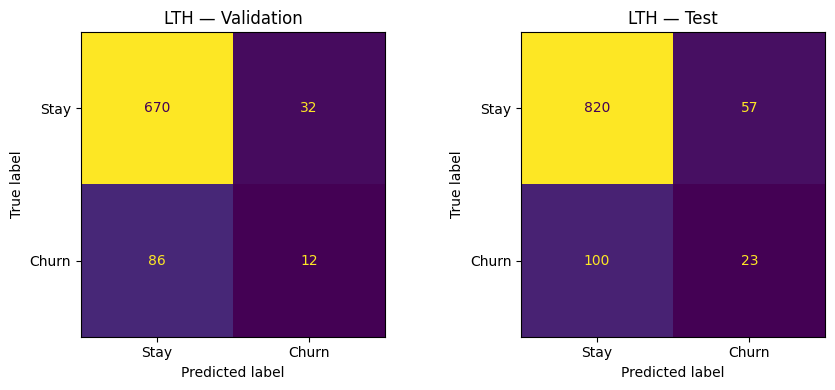

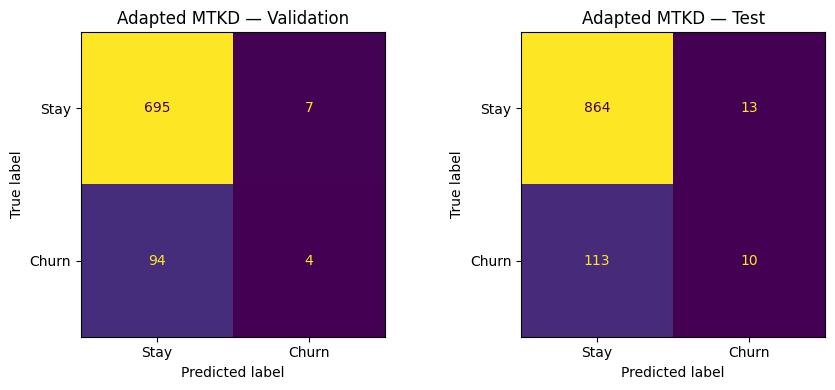

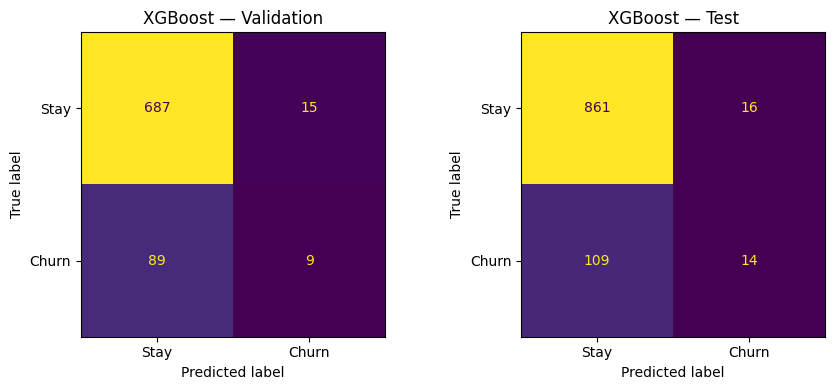

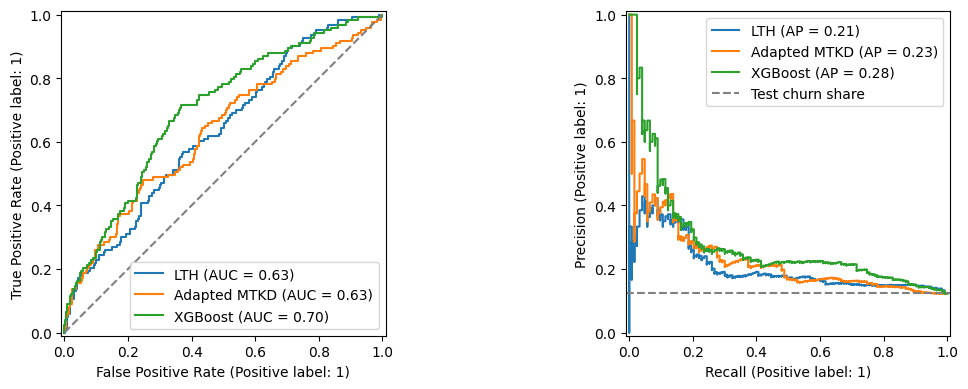

In [31]:
method_names = ['LTH', 'Adapted MTKD', 'XGBoost']
validation_probabilities = [val_lth, val_mtkd, val_xgb]
method_probabilities = [test_lth, test_mtkd, test_xgb]

for name, val_probabilities, test_probabilities in zip(
        method_names, validation_probabilities, method_probabilities):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))

    ConfusionMatrixDisplay.from_predictions(
        y_val, (val_probabilities >= THRESHOLD).astype(int), labels=[0, 1],
        display_labels=['Stay', 'Churn'], colorbar=False, ax=axes[0]
    )
    ConfusionMatrixDisplay.from_predictions(
        y_test, (test_probabilities >= THRESHOLD).astype(int), labels=[0, 1],
        display_labels=['Stay', 'Churn'], colorbar=False, ax=axes[1]
    )

    axes[0].set_title(name + ' — Validation')
    axes[1].set_title(name + ' — Test')
    plt.tight_layout()
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, probabilities in zip(method_names, method_probabilities):
    RocCurveDisplay.from_predictions(y_test, probabilities, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probabilities, name=name, ax=axes[1])

axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[1].axhline(y_test.mean(), linestyle='--', color='grey', label='Test churn share')
axes[1].legend()
plt.tight_layout()
plt.show()


,Model,Allocated parameters
0,Dense baseline,3938
1,LTH,3938
2,MTKD student,1458
3,Teacher 1,11970
4,Teacher 2,3938
5,Teacher 3,7778


LTH active parameters including biases: 1378
LTH total search time: 106.97 seconds
MTKD full training time: 120.93 seconds
XGBoost training time: 0.74 seconds


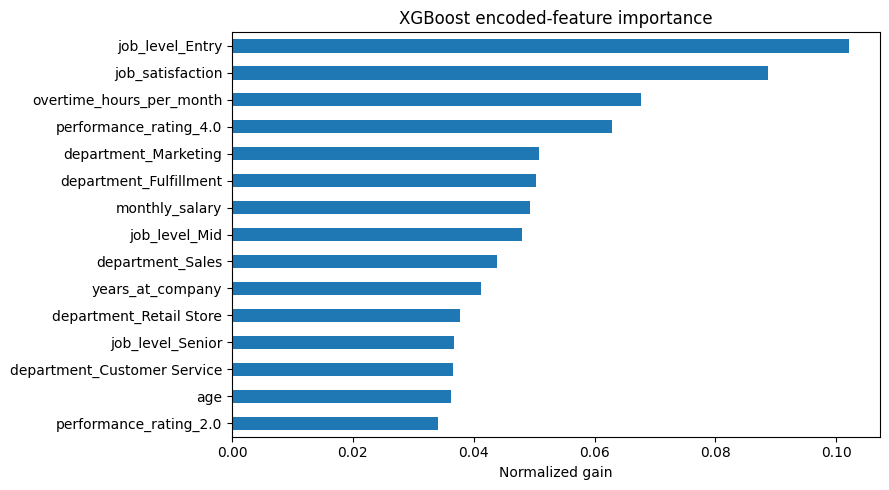

In [32]:
def parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters())

lth_active_weights = sum(int(mask.sum().item()) for mask in masks)
lth_biases = sum(layer.bias.numel() for layer in [lth_model[0], lth_model[2], lth_model[4]])

size_comparison = pd.DataFrame({
    'Model': ['Dense baseline', 'LTH', 'MTKD student', 'Teacher 1', 'Teacher 2', 'Teacher 3'],
    'Allocated parameters': [parameter_count(dense_model), parameter_count(lth_model),
                             parameter_count(student), parameter_count(teachers[0]),
                             parameter_count(teachers[1]), parameter_count(teachers[2])]
})

display(size_comparison)

print('LTH active parameters including biases:', lth_active_weights + lth_biases)
print('LTH total search time:', round(lth_seconds, 2), 'seconds')
print('MTKD full training time:', round(mtkd_seconds, 2), 'seconds')
print('XGBoost training time:', round(xgb_seconds, 2), 'seconds')

importance = pd.Series(xgb.feature_importances_, index=train_features.columns)

importance.nlargest(15).sort_values().plot.barh(figsize=(9, 5))
plt.xlabel('Normalized gain')
plt.title('XGBoost encoded-feature importance')
plt.tight_layout()
plt.show()


## 11. Compression, training cost, and feature interpretation
Allocated parameters count every tensor entry. Active connections count surviving weight-mask entries; unpruned biases remain active. Unstructured LTH masks retain the original dense allocation. The MTKD student has physically smaller layers and needs no teachers at inference. Its training cost still includes the teacher and aggregation stages.

Times below measure training plus epoch monitoring on this machine and exclude report plotting and data loading. The MTKD total includes fold preprocessing. LTH time includes its dense baseline and every pruning round. MTKD time includes OOF training, full teachers, aggregation and student training. They are not universal speed claims.

XGBoost feature importance below uses normalized **gain**: how much a split improved the training objective. It measures model usage, not a causal explanation. One-hot columns describe category-specific inputs. Correlated features can share importance.


**Code cell 32 — Compare model size, cost, and features**

Counts allocated neural parameters, counts active LTH parameters separately, reports training/monitoring times, and ranks encoded XGBoost features by gain.

**Output:** A size table, runtime messages, and an importance chart. Sparse masks do not reduce dense tensor allocation; importance does not show causation.


## 12. Read the findings and decide the next step
1. Compare validation AP first. The printed recommendation uses validation only. Check its fixed final test score as a monitoring estimate; it is no longer hidden during training.
2. For LTH, compare the final ticket with its dense baseline. Did AP stay close as active connections fell? Compare the same-mask random initialization control. One run offers limited evidence about initialization; a stronger study also needs random-mask controls and several seeds.
3. For MTKD, compare the distilled student with its labels-only control. Does distillation help the same small architecture? Compare it with teachers and the aggregation system. Student predictions can inherit teacher errors.
4. Compare compression and full training cost alongside predictive quality. Parameter counts for neural networks and tree counts for XGBoost are different quantities.
5. Read precision and recall before choosing an action. A churn prediction is a signal for investigation or support, not proof that someone will leave.

The code does not print a winning-ticket claim or a universal best model. The experiment has one split and one seed. Small score differences may be noise. The label relies on follow-up and predictor-timing assumptions, and a random split does not test generalization to a later workforce. Missing outcome dates can also hide incomplete records. High scores do not validate those assumptions.

**Recommended next study:** verify the target and feature timestamps first; then repeat evaluation across seeds or use a genuinely later cohort. If a business decision needs higher recall, choose a threshold on validation data with a stated error cost before evaluating once on a new test set. Keep fixed settings in this notebook unchanged when reporting this run.
